# Notebook 01 – Tiền xử lý dữ liệu Superstore

## Bước 3.1. Làm sạch dữ liệu

**Mục tiêu:** xử lý các vấn đề chất lượng của bảng Orders trước khi phân tích: ô trống, định dạng mã bưu chính, dòng trùng lặp, ngày tháng không hợp lý và giá trị ngoại lai.

- **Đầu vào:** `data/raw/Sample - Superstore.xls`, sheet `Orders` (file gốc, không bị sửa).
- **Đầu ra:** `data/processed/superstore_clean_3_1.csv`, `reports/3_1_cleaning_summary.csv`, `figures/3_1_boxplot_sales_profit.png`.
- Mỗi bước dưới đây in số liệu **trước** và **sau** khi xử lý.
- Cần cài: `pandas`, `numpy`, `matplotlib`, `seaborn`, `xlrd` (để đọc file `.xls`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

def vn(x, nd=0):
    # Định dạng số kiểu Việt Nam: dấu chấm ngăn nghìn, dấu phẩy thập phân
    return f"{x:,.{nd}f}".replace(",", "_").replace(".", ",").replace("_", ".")

# Gốc dự án: chạy notebook từ thư mục notebooks/ hoặc từ gốc dự án đều được
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "Sample - Superstore.xls"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"
REPORTS = ROOT / "reports"
for folder in (PROCESSED, FIGURES, REPORTS):
    folder.mkdir(parents=True, exist_ok=True)

summary = []  # ghi lại từng vấn đề để lập bảng tóm tắt ở bước 6
print("Gốc dự án:", ROOT)
print("File dữ liệu gốc tồn tại:", RAW.exists())

Gốc dự án: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore
File dữ liệu gốc tồn tại: True


### Bước 1. Đọc dữ liệu và khảo sát ban đầu

In [2]:
df_raw = pd.read_excel(RAW, sheet_name="Orders")
df = df_raw.copy()  # mọi thay đổi thực hiện trên bản sao, file gốc không bị sửa

print("Số dòng, số cột:", df.shape)
khao_sat = pd.DataFrame({"Kiểu dữ liệu": df.dtypes.astype(str), "Số ô trống": df.isna().sum()})
display(khao_sat)
print("Tổng số ô trống trong toàn bảng:", int(df.isna().sum().sum()))

Số dòng, số cột: (9994, 21)


,Kiểu dữ liệu,Số ô trống
Row ID,int64,0
Order ID,object,0
Order Date,datetime64[ns],0
Ship Date,datetime64[ns],0
Ship Mode,object,0
Customer ID,object,0
Customer Name,object,0
Segment,object,0
Country/Region,object,0
City,object,0


Tổng số ô trống trong toàn bảng: 11


### Bước 2. Xử lý Postal Code

Có hai vấn đề:

1. **11 ô trống**, đều thuộc Burlington, Vermont.
2. Mã bưu chính Mỹ gồm 5 chữ số, nhưng khi lưu dạng số thì các mã bắt đầu bằng 0 bị mất số 0 (ví dụ `05401` thành `5401`). Nếu để nguyên, mã sẽ sai khi nối hoặc so sánh với dữ liệu khác.

**Cách xử lý:** điền `05401` cho 11 ô trống, sau đó chuyển cả cột sang chuỗi 5 ký tự (`zfill(5)`).

In [3]:
mat_trong = df["Postal Code"].isna()
n_trong_truoc = int(mat_trong.sum())
print("TRƯỚC – Postal Code trống:", n_trong_truoc)
print("Thành phố, bang của các dòng trống:", df.loc[mat_trong, ["City", "State"]].drop_duplicates().values.tolist())
assert set(map(tuple, df.loc[mat_trong, ["City", "State"]].drop_duplicates().values)) == {("Burlington", "Vermont")}

n_mat_so_0 = int((df["Postal Code"].dropna() < 10000).sum())
print("TRƯỚC – mã bưu chính bị mất số 0 ở đầu (có ít hơn 5 chữ số):", n_mat_so_0, "dòng")

df["Postal Code"] = df["Postal Code"].fillna(0).astype(int).astype(str).str.zfill(5)
df.loc[mat_trong, "Postal Code"] = "05401"

print()
print("SAU – Postal Code trống:", int(df["Postal Code"].isna().sum()))
print("SAU – độ dài mã (số ký tự: số dòng):", df["Postal Code"].str.len().value_counts().to_dict())
print("SAU – kiểu dữ liệu:", df["Postal Code"].dtype)
print("Các dòng Burlington vừa điền:")
display(df.loc[mat_trong, ["Row ID", "City", "State", "Postal Code"]])

summary.append({"Vấn đề": "Postal Code bị trống", "Số dòng bị ảnh hưởng": n_trong_truoc,
                "Cách xử lý": "Điền '05401' (cả 11 dòng đều thuộc Burlington, Vermont)",
                "Kết quả": "0 ô trống"})
summary.append({"Vấn đề": "Postal Code mất số 0 ở đầu (lưu dạng số)", "Số dòng bị ảnh hưởng": n_mat_so_0,
                "Cách xử lý": "Chuyển cột sang chuỗi 5 ký tự (zfill)",
                "Kết quả": "Toàn bộ mã có đủ 5 ký tự"})

TRƯỚC – Postal Code trống: 11
Thành phố, bang của các dòng trống: [['Burlington', 'Vermont']]
TRƯỚC – mã bưu chính bị mất số 0 ở đầu (có ít hơn 5 chữ số): 438 dòng

SAU – Postal Code trống: 0
SAU – độ dài mã (số ký tự: số dòng): {5: 9994}
SAU – kiểu dữ liệu: object
Các dòng Burlington vừa điền:


,Row ID,City,State,Postal Code
2234,2235,Burlington,Vermont,05401
5274,5275,Burlington,Vermont,05401
8798,8799,Burlington,Vermont,05401
9146,9147,Burlington,Vermont,05401
9147,9148,Burlington,Vermont,05401
9148,9149,Burlington,Vermont,05401
9386,9387,Burlington,Vermont,05401
9387,9388,Burlington,Vermont,05401
9388,9389,Burlington,Vermont,05401
9389,9390,Burlington,Vermont,05401


### Bước 3. Xóa dòng trùng lặp

Cột `Row ID` là số thứ tự dòng nên luôn khác nhau; vì vậy khi tìm dòng trùng phải **bỏ cột này** ra khỏi phép so sánh. Dòng xuất hiện đầu tiên được giữ lại.

In [4]:
cot_so_sanh = [c for c in df.columns if c != "Row ID"]
nhom_trung = df.duplicated(subset=cot_so_sanh, keep=False)
bi_xoa = df.duplicated(subset=cot_so_sanh, keep="first")

n_truoc = len(df)
print("TRƯỚC – số dòng:", n_truoc)
print("Số dòng nằm trong nhóm trùng:", int(nhom_trung.sum()), "| số dòng sẽ bị xóa:", int(bi_xoa.sum()))
print("Các dòng trùng (dòng trên được giữ, dòng dưới bị xóa):")
display(df[nhom_trung].T)

n_trung = int(bi_xoa.sum())
row_id_bi_xoa = df.loc[bi_xoa, "Row ID"].tolist()
df = df.drop_duplicates(subset=cot_so_sanh, keep="first").reset_index(drop=True)

print()
print("SAU – số dòng:", len(df), "| Row ID đã xóa:", row_id_bi_xoa)
print("SAU – còn dòng trùng (bỏ Row ID):", int(df.duplicated(subset=cot_so_sanh).sum()))

summary.append({"Vấn đề": "Dòng trùng lặp (bỏ qua Row ID)", "Số dòng bị ảnh hưởng": n_trung,
                "Cách xử lý": "Xóa, giữ lại bản xuất hiện đầu tiên",
                "Kết quả": f"{vn(n_truoc)} → {vn(len(df))} dòng"})

TRƯỚC – số dòng: 9994
Số dòng nằm trong nhóm trùng: 2 | số dòng sẽ bị xóa: 1
Các dòng trùng (dòng trên được giữ, dòng dưới bị xóa):


,3405,3406
Row ID,3406,3407
Order ID,US-2016-150119,US-2016-150119
Order Date,2016-04-23 00:00:00,2016-04-23 00:00:00
Ship Date,2016-04-27 00:00:00,2016-04-27 00:00:00
Ship Mode,Standard Class,Standard Class
Customer ID,LB-16795,LB-16795
Customer Name,Laurel Beltran,Laurel Beltran
Segment,Home Office,Home Office
Country/Region,United States,United States
City,Columbus,Columbus



SAU – số dòng: 9993 | Row ID đã xóa: [3407]
SAU – còn dòng trùng (bỏ Row ID): 0


### Bước 4. Chuyển kiểu ngày và kiểm tra tính hợp lý

Chuyển `Order Date` và `Ship Date` sang kiểu `datetime`, sau đó kiểm tra ngày giao hàng không được sớm hơn ngày đặt hàng.

In [5]:
print("TRƯỚC – kiểu dữ liệu:", df[["Order Date", "Ship Date"]].dtypes.astype(str).to_dict())
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])
print("SAU – kiểu dữ liệu:", df[["Order Date", "Ship Date"]].dtypes.astype(str).to_dict())

print("Order Date từ", df["Order Date"].min().date(), "đến", df["Order Date"].max().date())
print("Ship Date  từ", df["Ship Date"].min().date(), "đến", df["Ship Date"].max().date())

vi_pham = df[df["Ship Date"] < df["Order Date"]]
n_vi_pham = len(vi_pham)
print("Số dòng có Ship Date < Order Date:", n_vi_pham)
if n_vi_pham:
    display(vi_pham[["Row ID", "Order ID", "Order Date", "Ship Date"]])
else:
    print("Không có dòng nào vi phạm, không cần xử lý.")
print("Số ngày từ đặt đến giao (nhỏ nhất, lớn nhất):", int((df["Ship Date"] - df["Order Date"]).dt.days.min()),
      int((df["Ship Date"] - df["Order Date"]).dt.days.max()))

summary.append({"Vấn đề": "Ship Date sớm hơn Order Date", "Số dòng bị ảnh hưởng": n_vi_pham,
                "Cách xử lý": "Chuyển sang kiểu datetime; không có dòng vi phạm nên không cần sửa",
                "Kết quả": "Ngày giao luôn không sớm hơn ngày đặt"})

TRƯỚC – kiểu dữ liệu: {'Order Date': 'datetime64[ns]', 'Ship Date': 'datetime64[ns]'}
SAU – kiểu dữ liệu: {'Order Date': 'datetime64[ns]', 'Ship Date': 'datetime64[ns]'}
Order Date từ 2016-01-03 đến 2019-12-30
Ship Date  từ 2016-01-07 đến 2020-01-05
Số dòng có Ship Date < Order Date: 0
Không có dòng nào vi phạm, không cần xử lý.
Số ngày từ đặt đến giao (nhỏ nhất, lớn nhất): 0 7


### Bước 5. Phát hiện ngoại lai Sales và Profit bằng IQR

Quy tắc IQR: một giá trị là ngoại lai nếu nằm ngoài khoảng `[Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR]`, trong đó `IQR = Q3 − Q1`.

In [6]:
def kiem_tra_iqr(cot):
    s = df[cot]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    duoi, tren = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    la = (s < duoi) | (s > tren)
    kq = {"Cột": cot, "Q1": q1, "Q3": q3, "IQR": iqr, "Ngưỡng dưới": duoi, "Ngưỡng trên": tren,
          "Ngoại lai dưới": int((s < duoi).sum()), "Ngoại lai trên": int((s > tren).sum()),
          "Tổng ngoại lai": int(la.sum())}
    return kq, la

kq_sales, la_sales = kiem_tra_iqr("Sales")
kq_profit, la_profit = kiem_tra_iqr("Profit")

# Chỉ gắn cờ, KHÔNG xóa dòng nào
df["is_outlier_sales"] = la_sales
df["is_outlier_profit"] = la_profit

bang_iqr = pd.DataFrame([kq_sales, kq_profit]).set_index("Cột")
display(bang_iqr.round(4))
for kq in (kq_sales, kq_profit):
    print(f"{kq['Cột']}: {vn(kq['Tổng ngoại lai'])} ngoại lai ({vn(100 * kq['Tổng ngoại lai'] / len(df), 1)}% số dòng) "
          f"– dưới ngưỡng: {vn(kq['Ngoại lai dưới'])}, trên ngưỡng: {vn(kq['Ngoại lai trên'])}")
print("Số dòng bị xóa ở bước này:", 0, "| số dòng hiện tại:", len(df))

,Q1,Q3,IQR,Ngưỡng dưới,Ngưỡng trên,Ngoại lai dưới,Ngoại lai trên,Tổng ngoại lai
Cột,,,,,,,,
Sales,17.280,209.940,192.660,-271.7100,498.9300,0,1167,1167
Profit,1.731,29.364,27.633,-39.7185,70.8135,604,1277,1881


Sales: 1.167 ngoại lai (11,7% số dòng) – dưới ngưỡng: 0, trên ngưỡng: 1.167
Profit: 1.881 ngoại lai (18,8% số dòng) – dưới ngưỡng: 604, trên ngưỡng: 1.277
Số dòng bị xóa ở bước này: 0 | số dòng hiện tại: 9993


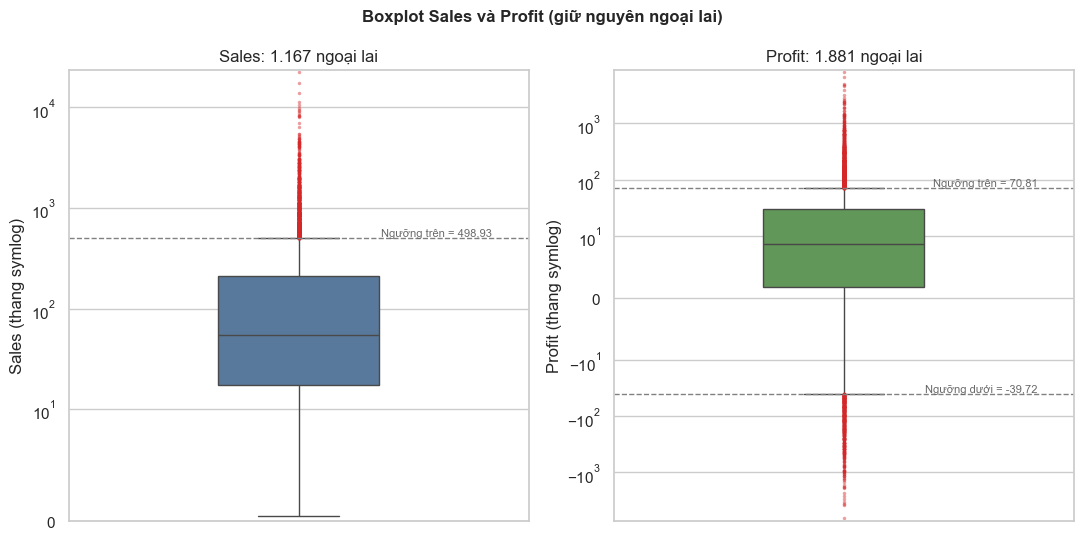

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/3_1_boxplot_sales_profit.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, kq, mau in zip(axes, (kq_sales, kq_profit), ("#4C78A8", "#59A14F")):
    cot = kq["Cột"]
    sns.boxplot(y=df[cot], ax=ax, color=mau, width=0.35, fliersize=2.5,
                flierprops=dict(marker="o", markerfacecolor="#D62728", markeredgecolor="none", alpha=0.45))
    ax.set_yscale("symlog", linthresh=10)  # thang symlog để nhìn rõ cả hộp lẫn ngoại lai
    for nguong, nhan in ((kq["Ngưỡng trên"], "Ngưỡng trên"), (kq["Ngưỡng dưới"], "Ngưỡng dưới")):
        if df[cot].min() <= nguong <= df[cot].max():
            ax.axhline(nguong, ls="--", lw=1, color="gray")
            ax.text(0.42, nguong, f"{nhan} = {vn(nguong, 2)}", va="bottom", ha="right", fontsize=8, color="dimgray")
    ax.set_title(f"{cot}: {vn(kq['Tổng ngoại lai'])} ngoại lai")
    if df[cot].min() >= 0:
        ax.set_ylim(bottom=0)  # Sales không âm, bỏ phần trục âm thừa
    ax.set_xlabel("")
    ax.set_ylabel(f"{cot} (thang symlog)")
fig.suptitle("Boxplot Sales và Profit (giữ nguyên ngoại lai)", fontsize=12, fontweight="bold")
fig.tight_layout()
duong_dan_hinh = FIGURES / "3_1_boxplot_sales_profit.png"
fig.savefig(duong_dan_hinh, dpi=200, facecolor="white")
plt.show()
print("Đã lưu hình:", duong_dan_hinh)

**Quyết định: GIỮ NGUYÊN các ngoại lai, chỉ gắn cờ `is_outlier_sales` và `is_outlier_profit`.**

- Đây là giao dịch thật (đơn hàng giá trị lớn, đơn bị lỗ do giảm giá cao), không phải lỗi nhập liệu.
- Xóa chúng sẽ làm mất đúng thông tin cần để trả lời Câu hỏi 1 và 2 (nhóm gây lỗ, ngưỡng giảm giá).
- Ảnh hưởng của ngoại lai lên các mô hình sẽ được xử lý ở bước 3.3 (biến đổi log, chuẩn hóa robust).

In [8]:
summary.append({"Vấn đề": "Ngoại lai Sales (IQR)", "Số dòng bị ảnh hưởng": kq_sales["Tổng ngoại lai"],
                "Cách xử lý": "Giữ nguyên, thêm cờ is_outlier_sales",
                "Kết quả": "Không xóa dòng nào"})
summary.append({"Vấn đề": "Ngoại lai Profit (IQR)", "Số dòng bị ảnh hưởng": kq_profit["Tổng ngoại lai"],
                "Cách xử lý": "Giữ nguyên, thêm cờ is_outlier_profit",
                "Kết quả": "Không xóa dòng nào"})

### Bước 6. Lưu kết quả

In [9]:
duong_dan_sach = PROCESSED / "superstore_clean_3_1.csv"
duong_dan_tom_tat = REPORTS / "3_1_cleaning_summary.csv"

df.to_csv(duong_dan_sach, index=False, encoding="utf-8-sig")

bang_tom_tat = pd.DataFrame(summary, columns=["Vấn đề", "Số dòng bị ảnh hưởng", "Cách xử lý", "Kết quả"])
bang_tom_tat.to_csv(duong_dan_tom_tat, index=False, encoding="utf-8-sig")

print("Đã lưu:", duong_dan_sach, "| kích thước:", df.shape)
print("Đã lưu:", duong_dan_tom_tat)
display(bang_tom_tat)

Đã lưu: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/data/processed/superstore_clean_3_1.csv | kích thước: (9993, 23)
Đã lưu: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/reports/3_1_cleaning_summary.csv


,Vấn đề,Số dòng bị ảnh hưởng,Cách xử lý,Kết quả
0,Postal Code bị trống,11,"Điền '05401' (cả 11 dòng đều thuộc Burlington,...",0 ô trống
1,Postal Code mất số 0 ở đầu (lưu dạng số),438,Chuyển cột sang chuỗi 5 ký tự (zfill),Toàn bộ mã có đủ 5 ký tự
2,Dòng trùng lặp (bỏ qua Row ID),1,"Xóa, giữ lại bản xuất hiện đầu tiên",9.994 → 9.993 dòng
3,Ship Date sớm hơn Order Date,0,Chuyển sang kiểu datetime; không có dòng vi ph...,Ngày giao luôn không sớm hơn ngày đặt
4,Ngoại lai Sales (IQR),1167,"Giữ nguyên, thêm cờ is_outlier_sales",Không xóa dòng nào
5,Ngoại lai Profit (IQR),1881,"Giữ nguyên, thêm cờ is_outlier_profit",Không xóa dòng nào


### Kiểm tra lại file đã lưu và đối chiếu kết quả kỳ vọng

Đọc lại file CSV, **chỉ định `Postal Code` là chuỗi** (nếu không, pandas sẽ đọc thành số và làm mất lại số 0 ở đầu), rồi đối chiếu với các kết quả đã biết.

In [10]:
kiem = pd.read_csv(duong_dan_sach, encoding="utf-8-sig", dtype={"Postal Code": str}, parse_dates=["Order Date", "Ship Date"])
assert kiem.shape == df.shape, "Kích thước file lưu khác dữ liệu trong bộ nhớ"
assert (kiem["Postal Code"].str.len() == 5).all(), "Có Postal Code không đủ 5 ký tự"
assert kiem["Postal Code"].isna().sum() == 0

def gan(a, b, tol=0.02): return bool(np.isclose(a, b, atol=tol))

kiem_tra = {
    "Postal Code trống = 11": n_trong_truoc == 11,
    "Mã mất số 0 đầu = 438": n_mat_so_0 == 438,
    "Dòng trùng = 1, còn 9.993 dòng": n_trung == 1 and len(df) == 9993,
    "Ship Date < Order Date = 0": n_vi_pham == 0,
    "Sales: Q1 = 17,28; Q3 = 209,94; ngưỡng trên = 498,93": gan(kq_sales["Q1"], 17.28) and gan(kq_sales["Q3"], 209.94) and gan(kq_sales["Ngưỡng trên"], 498.93),
    "Sales: 1.167 ngoại lai (sai lệch tối đa 1)": abs(kq_sales["Tổng ngoại lai"] - 1167) <= 1,
    "Profit: Q1 = 1,73; Q3 = 29,36; ngưỡng dưới = −39,72; ngưỡng trên = 70,82": (gan(kq_profit["Q1"], 1.73) and gan(kq_profit["Q3"], 29.36)
        and gan(kq_profit["Ngưỡng dưới"], -39.72) and gan(kq_profit["Ngưỡng trên"], 70.82)),
    "Profit: 1.881 ngoại lai (sai lệch tối đa 1)": abs(kq_profit["Tổng ngoại lai"] - 1881) <= 1,
}
for ten, ok in kiem_tra.items():
    print("ĐẠT " if ok else "LỆCH", "–", ten)
assert all(kiem_tra.values()), "Có kết quả lệch so với kỳ vọng, cần kiểm tra lại"
print()
print("Tất cả kết quả khớp kỳ vọng.")

ĐẠT  – Postal Code trống = 11
ĐẠT  – Mã mất số 0 đầu = 438
ĐẠT  – Dòng trùng = 1, còn 9.993 dòng
ĐẠT  – Ship Date < Order Date = 0
ĐẠT  – Sales: Q1 = 17,28; Q3 = 209,94; ngưỡng trên = 498,93
ĐẠT  – Sales: 1.167 ngoại lai (sai lệch tối đa 1)
ĐẠT  – Profit: Q1 = 1,73; Q3 = 29,36; ngưỡng dưới = −39,72; ngưỡng trên = 70,82
ĐẠT  – Profit: 1.881 ngoại lai (sai lệch tối đa 1)

Tất cả kết quả khớp kỳ vọng.


### Kết luận bước 3.1

- Đã xử lý xong 11 ô trống và định dạng của `Postal Code`, xóa 1 dòng trùng (còn 9.993 dòng), xác nhận ngày giao luôn không sớm hơn ngày đặt, và gắn cờ ngoại lai cho Sales và Profit mà không xóa dòng nào.
- Dữ liệu sau bước này lưu ở `data/processed/superstore_clean_3_1.csv`; khi đọc lại phải dùng `dtype={"Postal Code": str}`.
- Bước tiếp theo (3.2): tích hợp ba bảng Orders, Returns và People.

## Bước 3.2. Tích hợp dữ liệu

Bảng Orders chưa cho biết đơn nào bị trả hàng và quản lý nào phụ trách vùng. Thông tin đó nằm ở hai bảng khác: **Returns** (khóa `Order ID`) và **People** (khóa `Region`). Bước này nối chúng vào Orders bằng phép **left join**: giữ nguyên mọi dòng của Orders, chỉ thêm cột lấy từ bảng kia (dòng nào không tìm thấy khóa tương ứng thì được điền ô trống).

- **Đầu vào:** `data/processed/superstore_clean_3_1.csv` (kết quả bước 3.1) và hai sheet `Returns`, `People` của file gốc.
- **Đầu ra:** `reports/3_2_integration_summary.csv` (Bảng 3.2); dữ liệu sau tích hợp được lưu ở cuối bước 3.3.

In [11]:
# Đọc kết quả bước 3.1; Postal Code phải đọc dạng chuỗi để giữ số 0 đầu
df = pd.read_csv(PROCESSED / "superstore_clean_3_1.csv", encoding="utf-8-sig",
                 dtype={"Postal Code": str}, parse_dates=["Order Date", "Ship Date"])
print("Đọc kết quả bước 3.1:", df.shape)
assert df.shape == (9993, 23), "Kết quả bước 3.1 không đúng kích thước 9.993 x 23"
assert (df["Postal Code"].str.len() == 5).all()

tich_hop = []  # ghi lại từng bước để lập Bảng 3.2

Đọc kết quả bước 3.1: (9993, 23)


### 3.2.1. Bảng Returns: kiểm tra và bỏ trùng

**Vì sao Returns có dòng trùng?** Bảng Returns liệt kê đơn hàng bị trả, nhưng mỗi đơn bị ghi lặp lại theo số dòng sản phẩm của đơn đó trong Orders. Vì vậy 800 dòng chỉ ứng với một số đơn ít hơn nhiều. Ô dưới đây kiểm tra giả thuyết này trên dữ liệu thật, rồi bỏ trùng theo `Order ID` để mỗi đơn chỉ còn một dòng.

In [12]:
returns_raw = pd.read_excel(RAW, sheet_name="Returns")
n_ret_dong = len(returns_raw)
n_ret_don = returns_raw["Order ID"].nunique()
n_ret_trung = int(returns_raw.duplicated(subset="Order ID").sum())
print("TRƯỚC – số dòng Returns:", n_ret_dong, "| số Order ID khác nhau:", n_ret_don, "| số dòng trùng Order ID:", n_ret_trung)
print("Các giá trị của cột Returned:", returns_raw["Returned"].unique().tolist())

# Kiểm tra giả thuyết: số lần lặp trong Returns = số dòng sản phẩm của đơn trong Orders
lap_trong_returns = returns_raw.groupby("Order ID").size()
dong_trong_orders = df.groupby("Order ID").size().reindex(lap_trong_returns.index)
gia_thuyet_dung = bool((lap_trong_returns == dong_trong_orders).all())
print(f"Số lần lặp trong Returns đúng bằng số dòng sản phẩm của đơn trong Orders (cả {n_ret_don} đơn): {gia_thuyet_dung}")

returns = returns_raw.drop_duplicates(subset="Order ID")[["Order ID", "Returned"]].reset_index(drop=True)
print("SAU – số dòng Returns:", len(returns), "| còn trùng Order ID:", int(returns.duplicated(subset="Order ID").sum()))

ma_khong_khop = set(returns["Order ID"]) - set(df["Order ID"])
print("Số Order ID trong Returns không có trong Orders:", len(ma_khong_khop))
assert len(ma_khong_khop) == 0, "Có đơn bị trả không tồn tại trong Orders"

tich_hop.append({"Bước": "Bỏ trùng bảng Returns", "Bảng nguồn": "Returns", "Khóa nối": "Order ID",
                 "Kiểu join": "Không áp dụng", "Số dòng trước": n_ret_dong, "Số dòng sau": len(returns),
                 "Ghi chú": f"{n_ret_trung} dòng trùng khóa do mỗi đơn được ghi lặp theo số dòng sản phẩm; mọi Order ID đều có trong Orders"})

TRƯỚC – số dòng Returns: 800 | số Order ID khác nhau: 296 | số dòng trùng Order ID: 504
Các giá trị của cột Returned: ['Yes']
Số lần lặp trong Returns đúng bằng số dòng sản phẩm của đơn trong Orders (cả 296 đơn): True
SAU – số dòng Returns: 296 | còn trùng Order ID: 0
Số Order ID trong Returns không có trong Orders: 0


### 3.2.2. Nối Returns vào Orders (left join)

- `how="left"`: giữ đủ 9.993 dòng của Orders. Đơn không có trong Returns nhận ô trống ở cột `Returned`, sau đó được điền `"No"`.
- `validate="many_to_one"`: yêu cầu pandas kiểm tra quan hệ **nhiều – một**, tức nhiều dòng của Orders có thể cùng một `Order ID`, nhưng trong Returns mỗi `Order ID` chỉ được xuất hiện một lần. Nếu Returns còn trùng khóa, pandas sẽ báo lỗi thay vì âm thầm nhân số dòng lên.
- Tạo thêm cột `is_returned` (1 = bị trả, 0 = không) để dễ tính toán và huấn luyện mô hình.

In [13]:
n_truoc = len(df)
df = df.merge(returns, on="Order ID", how="left", validate="many_to_one")
df["Returned"] = df["Returned"].fillna("No")
df["is_returned"] = (df["Returned"] == "Yes").astype(int)

n_dong_tra = int(df["is_returned"].sum())
n_don_tra = df.loc[df["is_returned"] == 1, "Order ID"].nunique()
print("TRƯỚC – số dòng:", n_truoc, "| SAU – số dòng:", len(df))
print("Returned:", df["Returned"].value_counts().to_dict())
print(f"Số dòng bị trả: {n_dong_tra} (thuộc {n_don_tra} đơn)")

tich_hop.append({"Bước": "Nối Returns vào Orders", "Bảng nguồn": "Returns", "Khóa nối": "Order ID",
                 "Kiểu join": "left join (many_to_one)", "Số dòng trước": n_truoc, "Số dòng sau": len(df),
                 "Ghi chú": f"Thêm cột Returned (Yes/No) và is_returned (1/0); {n_dong_tra} dòng thuộc {n_don_tra} đơn bị trả"})

TRƯỚC – số dòng: 9993 | SAU – số dòng: 9993
Returned: {'No': 9193, 'Yes': 800}
Số dòng bị trả: 800 (thuộc 296 đơn)


### 3.2.3. Nối People vào Orders theo Region

Bảng People có 4 dòng, mỗi vùng một quản lý. Đổi tên cột `Person` thành `Manager` rồi nối theo `Region`, cũng với `validate="many_to_one"`.

In [14]:
people = pd.read_excel(RAW, sheet_name="People").rename(columns={"Person": "Manager"})
display(people)
assert people["Region"].is_unique, "Bảng People có Region bị lặp"

n_truoc = len(df)
df = df.merge(people, on="Region", how="left", validate="many_to_one")
print("TRƯỚC – số dòng:", n_truoc, "| SAU – số dòng:", len(df))

tich_hop.append({"Bước": "Nối People vào Orders", "Bảng nguồn": "People", "Khóa nối": "Region",
                 "Kiểu join": "left join (many_to_one)", "Số dòng trước": n_truoc, "Số dòng sau": len(df),
                 "Ghi chú": "Thêm cột Manager (đổi tên từ Person); 4 vùng ứng với 4 quản lý"})

,Manager,Region
0,Anna Andreadi,West
1,Chuck Magee,East
2,Kelly Williams,Central
3,Cassandra Brandow,South


TRƯỚC – số dòng: 9993 | SAU – số dòng: 9993


### 3.2.4. Kiểm tra sau tích hợp

In [15]:
assert len(df) == 9993, "Số dòng sau tích hợp khác 9.993"
assert df["Returned"].notna().all(), "Còn ô trống ở Returned"
assert df["Manager"].notna().all(), "Còn ô trống ở Manager"
print("Số dòng sau tích hợp:", len(df), "| số cột:", df.shape[1])
print("Ô trống ở Returned:", int(df["Returned"].isna().sum()), "| ô trống ở Manager:", int(df["Manager"].isna().sum()))

print("Bảng tần suất Returned:")
display(df["Returned"].value_counts().rename_axis("Returned").to_frame("Số dòng"))
print("Bảng Region → Manager:")
display(df[["Region", "Manager"]].drop_duplicates().sort_values("Region").reset_index(drop=True))

Số dòng sau tích hợp: 9993 | số cột: 26
Ô trống ở Returned: 0 | ô trống ở Manager: 0
Bảng tần suất Returned:


,Số dòng
Returned,
No,9193
Yes,800


Bảng Region → Manager:


,Region,Manager
0,Central,Kelly Williams
1,East,Chuck Magee
2,South,Cassandra Brandow
3,West,Anna Andreadi


### 3.2.5. Bảng tóm tắt tích hợp (Bảng 3.2)

In [16]:
bang_3_2 = pd.DataFrame(tich_hop, columns=["Bước", "Bảng nguồn", "Khóa nối", "Kiểu join", "Số dòng trước", "Số dòng sau", "Ghi chú"])
bang_3_2.to_csv(REPORTS / "3_2_integration_summary.csv", index=False, encoding="utf-8-sig")
print("Đã lưu:", REPORTS / "3_2_integration_summary.csv")
display(bang_3_2)

Đã lưu: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/reports/3_2_integration_summary.csv


,Bước,Bảng nguồn,Khóa nối,Kiểu join,Số dòng trước,Số dòng sau,Ghi chú
0,Bỏ trùng bảng Returns,Returns,Order ID,Không áp dụng,800,296,504 dòng trùng khóa do mỗi đơn được ghi lặp th...
1,Nối Returns vào Orders,Returns,Order ID,left join (many_to_one),9993,9993,Thêm cột Returned (Yes/No) và is_returned (1/0...
2,Nối People vào Orders,People,Region,left join (many_to_one),9993,9993,Thêm cột Manager (đổi tên từ Person); 4 vùng ứ...


## Bước 3.3. Biến đổi dữ liệu

Bước này tạo các đặc trưng mới, giảm độ lệch của Sales, chuẩn hóa thang đo và mã hóa biến phân loại. Cuối bước lưu **hai file**:

- `superstore_integrated_3_3.csv`: dữ liệu đã tích hợp và có đặc trưng mới, **chưa** chuẩn hóa hay one-hot, dễ đọc, dùng cho EDA và dashboard.
- `superstore_model_ready.csv`: bản đã chuẩn hóa và mã hóa, dùng cho Machine Learning.

### 3.3.1. Tạo đặc trưng mới

| Đặc trưng | Công thức | Ý nghĩa |
|---|---|---|
| `Ship Days` | Ship Date − Order Date | Số ngày từ đặt đến giao hàng |
| `Order Year`, `Order Quarter`, `Order Month`, `Order Weekday` | lấy từ Order Date | Phân tích xu hướng và mùa vụ (Weekday: 0 = Thứ Hai … 6 = Chủ Nhật) |
| `Profit Margin` | Profit / Sales | Tỷ suất lợi nhuận của dòng hàng |
| `Unit Price` | Sales / Quantity | Giá bán mỗi đơn vị **sau** giảm giá |

In [17]:
assert (df["Sales"] > 0).all() and (df["Quantity"] > 0).all()  # tránh chia cho 0

df["Ship Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Order Year"] = df["Order Date"].dt.year
df["Order Quarter"] = df["Order Date"].dt.quarter
df["Order Month"] = df["Order Date"].dt.month
df["Order Weekday"] = df["Order Date"].dt.dayofweek
df["Profit Margin"] = df["Profit"] / df["Sales"]
df["Unit Price"] = df["Sales"] / df["Quantity"]

cot_moi = ["Ship Days", "Order Year", "Order Quarter", "Order Month", "Order Weekday", "Profit Margin", "Unit Price"]
thong_ke_moi = df[cot_moi].agg(["min", "mean", "max"]).T
display(thong_ke_moi.round(4))

,min,mean,max
Ship Days,0.000,3.9581,7.00
Order Year,2016.000,2017.7224,2019.00
Order Quarter,1.000,2.8824,4.00
Order Month,1.000,7.8101,12.00
Order Weekday,0.000,2.7123,6.00
Profit Margin,-2.750,0.1203,0.50
Unit Price,0.336,60.9116,3773.08


### 3.3.2. Biến đổi log cho Sales

`Sales` lệch phải rất mạnh: đa số đơn có giá trị nhỏ, nhưng một số ít đơn rất lớn (tới hơn 22.000) kéo phân phối về phía phải. Phép biến đổi `log1p(x) = log(1 + x)` nén các giá trị lớn lại, làm phân phối gần đối xứng hơn và giảm ảnh hưởng của các ngoại lai đã phát hiện ở bước 3.1. Dùng `log1p` thay vì `log` để an toàn khi giá trị bằng 0.

**Độ lệch (skewness)** đo mức bất đối xứng của phân phối: 0 là đối xứng, số dương lớn là lệch phải.

Độ lệch (skewness) của Sales – trước log: 12,97 | sau log1p: 0,28


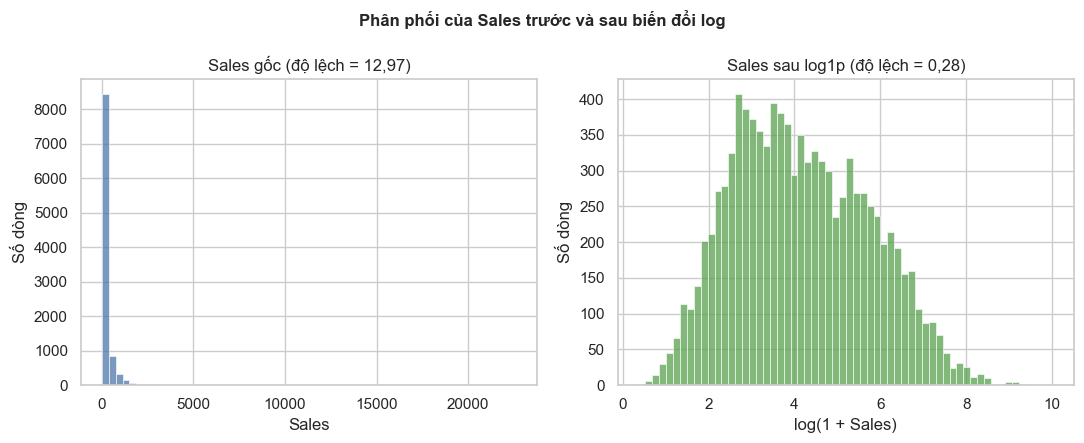

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/3_3_log_sales.png


In [18]:
df["Sales_log"] = np.log1p(df["Sales"])
skew_truoc, skew_sau = df["Sales"].skew(), df["Sales_log"].skew()
print(f"Độ lệch (skewness) của Sales – trước log: {vn(skew_truoc, 2)} | sau log1p: {vn(skew_sau, 2)}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.histplot(df["Sales"], bins=60, ax=axes[0], color="#4C78A8")
axes[0].set_title(f"Sales gốc (độ lệch = {vn(skew_truoc, 2)})")
axes[0].set_xlabel("Sales")
sns.histplot(df["Sales_log"], bins=60, ax=axes[1], color="#59A14F")
axes[1].set_title(f"Sales sau log1p (độ lệch = {vn(skew_sau, 2)})")
axes[1].set_xlabel("log(1 + Sales)")
for ax in axes:
    ax.set_ylabel("Số dòng")
fig.suptitle("Phân phối của Sales trước và sau biến đổi log", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "3_3_log_sales.png", dpi=200, facecolor="white")
plt.show()
print("Đã lưu hình:", FIGURES / "3_3_log_sales.png")

# Bản dữ liệu tích hợp: đã có đặc trưng mới, CHƯA chuẩn hóa và mã hóa (lưu ở bước 3.3.5)
df_tich_hop = df.copy()

### 3.3.3. Chuẩn hóa các cột số

Các cột số có thang đo rất khác nhau (Sales tới hàng chục nghìn, Discount chỉ từ 0 đến 0,8). Nhiều thuật toán (K-Means, hồi quy logistic…) nhạy với thang đo nên cần đưa về cùng thang:

- **Min-Max:** `(x − min) / (max − min)`, đưa giá trị về đoạn [0, 1]. Thêm hậu tố `_minmax`.
- **Z-score:** `(x − trung bình) / độ lệch chuẩn`, đưa về trung bình 0 và độ lệch chuẩn 1. Thêm hậu tố `_z`.

> **Ghi chú quan trọng về rò rỉ dữ liệu (data leakage):** ở đây scaler được fit trên **toàn bộ** dữ liệu chỉ để minh họa kỹ thuật. Khi huấn luyện mô hình ở mục 4.3, scaler phải được fit **chỉ trên tập huấn luyện** rồi mới áp dụng cho tập kiểm tra. Nếu fit trên cả hai tập, thông tin của tập kiểm tra (min, max, trung bình) lọt vào quá trình huấn luyện làm kết quả đánh giá đẹp hơn thực tế.

In [19]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

cot_so = ["Sales", "Quantity", "Discount", "Profit", "Ship Days", "Unit Price"]
minmax = MinMaxScaler().fit_transform(df[cot_so])
zscore = StandardScaler().fit_transform(df[cot_so])
for i, c in enumerate(cot_so):
    df[f"{c}_minmax"] = minmax[:, i]
    df[f"{c}_z"] = zscore[:, i]

def mo_ta(serie, ten):
    return {"Cột": ten, "min": serie.min(), "max": serie.max(), "mean": serie.mean(), "std": serie.std(ddof=0)}

dong = []
for c in ["Sales", "Profit", "Ship Days"]:
    dong += [mo_ta(df[c], c), mo_ta(df[f"{c}_minmax"], f"{c}_minmax"), mo_ta(df[f"{c}_z"], f"{c}_z")]
so_sanh = pd.DataFrame(dong).set_index("Cột")
print("So sánh trước và sau chuẩn hóa (std tính theo ddof=0):")
display(so_sanh.round(4))
assert np.allclose(df[[f"{c}_minmax" for c in cot_so]].min(), 0) and np.allclose(df[[f"{c}_minmax" for c in cot_so]].max(), 1)
assert np.allclose(df[[f"{c}_z" for c in cot_so]].mean(), 0, atol=1e-9)

So sánh trước và sau chuẩn hóa (std tính theo ddof=0):


,min,max,mean,std
Cột,,,,
Sales,0.4440,22638.4800,229.8528,623.2449
Sales_minmax,0.0000,1.0000,0.0101,0.0275
Sales_z,-0.3681,35.9548,-0.0000,1.0000
Profit,-6599.9780,8399.9760,28.6610,234.2598
Profit_minmax,0.0000,1.0000,0.4419,0.0156
Profit_z,-28.2961,35.7352,-0.0000,1.0000
Ship Days,0.0000,7.0000,3.9581,1.7479
Ship Days_minmax,0.0000,1.0000,0.5654,0.2497
Ship Days_z,-2.2644,1.7403,-0.0000,1.0000


### 3.3.4. Mã hóa biến phân loại

Thuật toán học máy chỉ làm việc với số nên phải mã hóa các cột chữ:

- **Label (ordinal) encoding** cho `Ship Mode`, vì các loại có **thứ tự** tốc độ giao hàng: `Same Day = 0`, `First Class = 1`, `Second Class = 2`, `Standard Class = 3`. Kết quả nằm ở cột `ShipMode_code`.
- **One-hot encoding** cho `Segment`, `Region`, `Category`, `Sub-Category`, vì các loại **không có thứ tự**. Mỗi loại thành một cột 0/1. Dùng `drop_first=True` để bỏ một cột (tránh dư thừa: biết các cột còn lại là suy ra được cột bị bỏ).
- **Không mã hóa** các cột định danh (`Order ID`, `Customer ID`, `Product ID`, `Customer Name`, `Product Name`) và cột văn bản, vì chúng không mang ý nghĩa phân loại cho mô hình.

In [20]:
thu_tu_ship = {"Same Day": 0, "First Class": 1, "Second Class": 2, "Standard Class": 3}
df["ShipMode_code"] = df["Ship Mode"].map(thu_tu_ship)
assert df["ShipMode_code"].notna().all()

cot_one_hot = ["Segment", "Region", "Category", "Sub-Category"]
print("Số giá trị khác nhau:", {c: int(df[c].nunique()) for c in ["Ship Mode"] + cot_one_hot})

so_cot_truoc = df.shape[1]
one_hot = pd.get_dummies(df[cot_one_hot], drop_first=True, dtype=int)
so_cot_one_hot = {c: sum(col.startswith(c + "_") for col in one_hot.columns) for c in cot_one_hot}
print("Số cột one-hot tạo ra (drop_first=True):", so_cot_one_hot, "| tổng:", one_hot.shape[1])

cot_dinh_danh = ["Row ID", "Order ID", "Customer ID", "Product ID"]   # giữ nguyên để truy vết, KHÔNG mã hóa
cot_so_goc = ["Sales", "Quantity", "Discount", "Profit", "Ship Days", "Unit Price", "Profit Margin", "Sales_log"]
cot_thoi_gian = ["Order Year", "Order Quarter", "Order Month", "Order Weekday"]
cot_chuan_hoa = [f"{c}_minmax" for c in cot_so] + [f"{c}_z" for c in cot_so]
cot_khac = ["ShipMode_code", "is_returned", "is_outlier_sales", "is_outlier_profit"]

model_ready = pd.concat([df[cot_dinh_danh + cot_so_goc + cot_thoi_gian + cot_chuan_hoa + cot_khac], one_hot], axis=1)
model_ready[["is_outlier_sales", "is_outlier_profit"]] = model_ready[["is_outlier_sales", "is_outlier_profit"]].astype(int)

cot_bo = [c for c in df.columns if c not in model_ready.columns]
print(f"Số cột TRƯỚC mã hóa: {so_cot_truoc} | SAU (bản model_ready): {model_ready.shape[1]}")
print("Các cột không đưa vào model_ready (văn bản, ngày gốc, cột đã được mã hóa thay thế, cột trùng thông tin):")
print(cot_bo)

assert model_ready.isna().sum().sum() == 0
assert model_ready.drop(columns=cot_dinh_danh).select_dtypes(exclude="number").shape[1] == 0, "Còn cột không phải số"

Số giá trị khác nhau: {'Ship Mode': 4, 'Segment': 3, 'Region': 4, 'Category': 3, 'Sub-Category': 17}
Số cột one-hot tạo ra (drop_first=True): {'Segment': 2, 'Region': 3, 'Category': 2, 'Sub-Category': 16} | tổng: 23
Số cột TRƯỚC mã hóa: 47 | SAU (bản model_ready): 55
Các cột không đưa vào model_ready (văn bản, ngày gốc, cột đã được mã hóa thay thế, cột trùng thông tin):
['Order Date', 'Ship Date', 'Ship Mode', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Product Name', 'Returned', 'Manager']


### 3.3.5. Lưu kết quả

> **Lưu ý khi dùng `superstore_model_ready.csv` ở mục 4.3:** khi dự đoán đơn lỗ (`Profit < 0`), **không** dùng `Profit`, `Profit Margin`, `Profit_minmax`, `Profit_z` làm đặc trưng vì nhãn suy ra từ chính Profit (rò rỉ dữ liệu). Các cột `_minmax` và `_z` chỉ để minh họa; khi huấn luyện hãy dùng cột số gốc và fit scaler chỉ trên tập huấn luyện.

In [21]:
duong_tich_hop = PROCESSED / "superstore_integrated_3_3.csv"
duong_model = PROCESSED / "superstore_model_ready.csv"
df_tich_hop.to_csv(duong_tich_hop, index=False, encoding="utf-8-sig")
model_ready.to_csv(duong_model, index=False, encoding="utf-8-sig")

f = lambda x, nd=2: vn(x, nd)
ud = df_tich_hop
bang_3_3 = pd.DataFrame([
    {"Kỹ thuật": "Tạo đặc trưng thời gian", "Cột áp dụng": "Ship Days; Order Year, Order Quarter, Order Month, Order Weekday",
     "Công thức/Phương pháp": "Ship Days = Ship Date − Order Date (ngày); năm, quý, tháng, thứ trong tuần lấy từ Order Date",
     "Mục đích": "Phân tích xu hướng, mùa vụ và thời gian giao hàng",
     "Kết quả": f"Ship Days: min {ud['Ship Days'].min()}, trung bình {f(ud['Ship Days'].mean())}, max {ud['Ship Days'].max()}; thêm 4 cột thời gian"},
    {"Kỹ thuật": "Tạo tỷ suất lợi nhuận", "Cột áp dụng": "Profit Margin", "Công thức/Phương pháp": "Profit / Sales",
     "Mục đích": "So sánh hiệu quả sinh lời giữa các dòng hàng có giá trị khác nhau",
     "Kết quả": f"min {f(ud['Profit Margin'].min())}, trung bình {f(ud['Profit Margin'].mean())}, max {f(ud['Profit Margin'].max())}"},
    {"Kỹ thuật": "Tạo đơn giá", "Cột áp dụng": "Unit Price", "Công thức/Phương pháp": "Sales / Quantity",
     "Mục đích": "Giá bán mỗi đơn vị sau giảm giá",
     "Kết quả": f"min {f(ud['Unit Price'].min())}, trung bình {f(ud['Unit Price'].mean())}, max {f(ud['Unit Price'].max())}"},
    {"Kỹ thuật": "Biến đổi log", "Cột áp dụng": "Sales → Sales_log", "Công thức/Phương pháp": "log(1 + Sales)",
     "Mục đích": "Giảm độ lệch phải và ảnh hưởng của ngoại lai",
     "Kết quả": f"Độ lệch {f(skew_truoc)} → {f(skew_sau)}"},
    {"Kỹ thuật": "Chuẩn hóa Min-Max", "Cột áp dụng": ", ".join(cot_so), "Công thức/Phương pháp": "(x − min) / (max − min)",
     "Mục đích": "Đưa các cột về cùng thang [0, 1]", "Kết quả": f"{len(cot_so)} cột hậu tố _minmax, giá trị trong [0, 1]"},
    {"Kỹ thuật": "Chuẩn hóa Z-score", "Cột áp dụng": ", ".join(cot_so), "Công thức/Phương pháp": "(x − trung bình) / độ lệch chuẩn",
     "Mục đích": "Đưa các cột về trung bình 0, độ lệch chuẩn 1", "Kết quả": f"{len(cot_so)} cột hậu tố _z"},
    {"Kỹ thuật": "Mã hóa thứ tự (label encoding)", "Cột áp dụng": "Ship Mode → ShipMode_code",
     "Công thức/Phương pháp": "Same Day = 0, First Class = 1, Second Class = 2, Standard Class = 3",
     "Mục đích": "Giữ thứ tự tốc độ giao hàng", "Kết quả": "1 cột, 4 giá trị"},
    {"Kỹ thuật": "Mã hóa one-hot", "Cột áp dụng": "Segment, Region, Category", "Công thức/Phương pháp": "get_dummies, drop_first=True",
     "Mục đích": "Đưa biến phân loại không có thứ tự về dạng số",
     "Kết quả": f"{so_cot_one_hot['Segment'] + so_cot_one_hot['Region'] + so_cot_one_hot['Category']} cột (Segment {so_cot_one_hot['Segment']}, Region {so_cot_one_hot['Region']}, Category {so_cot_one_hot['Category']})"},
    {"Kỹ thuật": "Mã hóa one-hot", "Cột áp dụng": "Sub-Category", "Công thức/Phương pháp": "get_dummies, drop_first=True",
     "Mục đích": "Đưa nhóm hàng (17 giá trị) về dạng số", "Kết quả": f"{so_cot_one_hot['Sub-Category']} cột"},
], columns=["Kỹ thuật", "Cột áp dụng", "Công thức/Phương pháp", "Mục đích", "Kết quả"])
bang_3_3.to_csv(REPORTS / "3_3_transformation_summary.csv", index=False, encoding="utf-8-sig")

print("Đã lưu:", duong_tich_hop, "| kích thước:", df_tich_hop.shape)
print("Đã lưu:", duong_model, "| kích thước:", model_ready.shape)
print("Đã lưu:", REPORTS / "3_3_transformation_summary.csv")
display(bang_3_3)

Đã lưu: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/data/processed/superstore_integrated_3_3.csv | kích thước: (9993, 34)
Đã lưu: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/data/processed/superstore_model_ready.csv | kích thước: (9993, 55)
Đã lưu: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/reports/3_3_transformation_summary.csv


,Kỹ thuật,Cột áp dụng,Công thức/Phương pháp,Mục đích,Kết quả
0,Tạo đặc trưng thời gian,"Ship Days; Order Year, Order Quarter, Order Mo...",Ship Days = Ship Date − Order Date (ngày); năm...,"Phân tích xu hướng, mùa vụ và thời gian giao hàng","Ship Days: min 0, trung bình 3,96, max 7; thêm..."
1,Tạo tỷ suất lợi nhuận,Profit Margin,Profit / Sales,So sánh hiệu quả sinh lời giữa các dòng hàng c...,"min -2,75, trung bình 0,12, max 0,50"
2,Tạo đơn giá,Unit Price,Sales / Quantity,Giá bán mỗi đơn vị sau giảm giá,"min 0,34, trung bình 60,91, max 3.773,08"
3,Biến đổi log,Sales → Sales_log,log(1 + Sales),Giảm độ lệch phải và ảnh hưởng của ngoại lai,"Độ lệch 12,97 → 0,28"
4,Chuẩn hóa Min-Max,"Sales, Quantity, Discount, Profit, Ship Days, ...",(x − min) / (max − min),"Đưa các cột về cùng thang [0, 1]","6 cột hậu tố _minmax, giá trị trong [0, 1]"
5,Chuẩn hóa Z-score,"Sales, Quantity, Discount, Profit, Ship Days, ...",(x − trung bình) / độ lệch chuẩn,"Đưa các cột về trung bình 0, độ lệch chuẩn 1",6 cột hậu tố _z
6,Mã hóa thứ tự (label encoding),Ship Mode → ShipMode_code,"Same Day = 0, First Class = 1, Second Class = ...",Giữ thứ tự tốc độ giao hàng,"1 cột, 4 giá trị"
7,Mã hóa one-hot,"Segment, Region, Category","get_dummies, drop_first=True",Đưa biến phân loại không có thứ tự về dạng số,"7 cột (Segment 2, Region 3, Category 2)"
8,Mã hóa one-hot,Sub-Category,"get_dummies, drop_first=True",Đưa nhóm hàng (17 giá trị) về dạng số,16 cột


### Kiểm tra lại file đã lưu và đối chiếu kết quả kỳ vọng

In [22]:
a = pd.read_csv(duong_tich_hop, encoding="utf-8-sig", dtype={"Postal Code": str}, parse_dates=["Order Date", "Ship Date"])
b = pd.read_csv(duong_model, encoding="utf-8-sig")
assert a.shape == df_tich_hop.shape and b.shape == model_ready.shape
assert (a["Postal Code"].str.len() == 5).all() and a[["Returned", "Manager"]].notna().all().all()
assert b.isna().sum().sum() == 0

quan_ly = df_tich_hop[["Region", "Manager"]].drop_duplicates().set_index("Region")["Manager"].to_dict()
kiem_tra = {
    "Returns: 800 dòng → 296 đơn, bỏ 504 dòng trùng": (n_ret_dong, n_ret_don, n_ret_trung) == (800, 296, 504),
    "Returns: 0 mã không khớp với Orders": len(ma_khong_khop) == 0,
    "Sau join: 9.993 dòng": len(df_tich_hop) == 9993,
    "Returned = Yes ở 800 dòng (296 đơn), No ở 9.193 dòng": (n_dong_tra, n_don_tra, int((df_tich_hop['Returned'] == 'No').sum())) == (800, 296, 9193),
    "Manager: West–Anna Andreadi, East–Chuck Magee, Central–Kelly Williams, South–Cassandra Brandow":
        quan_ly == {"West": "Anna Andreadi", "East": "Chuck Magee", "Central": "Kelly Williams", "South": "Cassandra Brandow"},
    "Ship Days: min 0, trung bình ≈ 3,96, max 7": (df_tich_hop["Ship Days"].min() == 0 and df_tich_hop["Ship Days"].max() == 7
                                                    and abs(df_tich_hop["Ship Days"].mean() - 3.96) < 0.01),
    "Profit Margin: min ≈ −2,75, max 0,50, trung bình ≈ 0,12": (abs(df_tich_hop["Profit Margin"].min() + 2.75) < 0.01
                                                                and abs(df_tich_hop["Profit Margin"].max() - 0.50) < 0.01
                                                                and abs(df_tich_hop["Profit Margin"].mean() - 0.12) < 0.01),
    "Sales: min 0,444": abs(df_tich_hop["Sales"].min() - 0.444) < 0.001,
    "Độ lệch Sales ≈ 12,97 trước log → ≈ 0,28 sau log1p": abs(skew_truoc - 12.97) < 0.02 and abs(skew_sau - 0.28) < 0.02,
    "Số giá trị: Ship Mode 4, Segment 3, Region 4, Category 3, Sub-Category 17":
        [df_tich_hop[c].nunique() for c in ["Ship Mode", "Segment", "Region", "Category", "Sub-Category"]] == [4, 3, 4, 3, 17],
}
for ten, ok in kiem_tra.items():
    print("ĐẠT " if ok else "LỆCH", "–", ten)
assert all(kiem_tra.values()), "Có kết quả lệch so với kỳ vọng, cần kiểm tra lại"
print()
print("Tất cả kết quả khớp kỳ vọng.")

ĐẠT  – Returns: 800 dòng → 296 đơn, bỏ 504 dòng trùng
ĐẠT  – Returns: 0 mã không khớp với Orders
ĐẠT  – Sau join: 9.993 dòng
ĐẠT  – Returned = Yes ở 800 dòng (296 đơn), No ở 9.193 dòng
ĐẠT  – Manager: West–Anna Andreadi, East–Chuck Magee, Central–Kelly Williams, South–Cassandra Brandow
ĐẠT  – Ship Days: min 0, trung bình ≈ 3,96, max 7
ĐẠT  – Profit Margin: min ≈ −2,75, max 0,50, trung bình ≈ 0,12
ĐẠT  – Sales: min 0,444
ĐẠT  – Độ lệch Sales ≈ 12,97 trước log → ≈ 0,28 sau log1p
ĐẠT  – Số giá trị: Ship Mode 4, Segment 3, Region 4, Category 3, Sub-Category 17

Tất cả kết quả khớp kỳ vọng.


### Kết luận bước 3.2 và 3.3

- **3.2:** Returns từ 800 dòng còn 296 đơn (bỏ 504 dòng trùng); sau khi nối với Returns và People, bảng vẫn có 9.993 dòng, có thêm các cột `Returned`, `is_returned`, `Manager`, không còn ô trống.
- **3.3:** đã tạo `Ship Days`, `Order Year/Quarter/Month/Weekday`, `Profit Margin`, `Unit Price`, `Sales_log`; chuẩn hóa 6 cột số (Min-Max và Z-score); mã hóa `Ship Mode` (label) và `Segment`, `Region`, `Category`, `Sub-Category` (one-hot).
- **Hai file đầu ra:** `superstore_integrated_3_3.csv` cho EDA và dashboard; `superstore_model_ready.csv` cho Machine Learning.
- Bước tiếp theo (3.4): rút gọn dữ liệu (bỏ cột dư thừa, chọn đặc trưng, PCA, gộp theo đơn hàng và khách hàng).

## Bước 3.4. Rút gọn dữ liệu

Rút gọn dữ liệu là giảm kích thước dữ liệu mà vẫn giữ được thông tin cần thiết cho phân tích. Bước này rút gọn theo **cột** (bỏ cột không mang thông tin, xét mức độ trùng lặp giữa các biến, PCA) và theo **dòng** (gộp theo đơn hàng và theo khách hàng).

- **Đầu vào:** `data/processed/superstore_integrated_3_3.csv` (kết quả bước 3.3).
- **Đầu ra:** `orders_level.csv`, `customers_level.csv`, hai hình `3_4_correlation_heatmap.png` và `3_4_pca_scree.png`, cùng các bảng trong `reports/`.

### 3.4.1. Rút gọn theo cột: cột hằng và cột dư thừa

- **Cột hằng** là cột chỉ có một giá trị duy nhất cho mọi dòng. Cột này không giúp phân biệt các dòng với nhau nên không có giá trị phân tích và có thể xóa.
- **Cột dư thừa** là cột không mang thông tin mới. `Row ID` chỉ là số thứ tự dòng; `Customer Name` có quan hệ 1–1 với `Customer ID` (mỗi mã ứng với đúng một tên và ngược lại) nên đã được `Customer ID` đại diện. Quan hệ 1–1 được kiểm tra bằng code trước khi xóa.

In [23]:
duong_model = PROCESSED / "superstore_model_ready.csv"
mtime_model_truoc = duong_model.stat().st_mtime  # để chứng minh file model_ready không bị sửa ở bước này

df = pd.read_csv(PROCESSED / "superstore_integrated_3_3.csv", encoding="utf-8-sig",
                 dtype={"Postal Code": str}, parse_dates=["Order Date", "Ship Date"])
assert df.shape == (9993, 34), "Kết quả bước 3.3 không đúng kích thước 9.993 x 34"
so_cot_truoc = df.shape[1]

cot_hang = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print("Cột hằng:", cot_hang, "| giá trị duy nhất:", {c: df[c].iloc[0] for c in cot_hang})

n_id, n_ten = df["Customer ID"].nunique(), df["Customer Name"].nunique()
n_cap = len(df[["Customer ID", "Customer Name"]].drop_duplicates())
quan_he_1_1 = (n_id == n_ten == n_cap)
print(f"Customer ID: {n_id} giá trị | Customer Name: {n_ten} giá trị | số cặp khác nhau: {n_cap} → quan hệ 1–1: {quan_he_1_1}")
print("Row ID là duy nhất:", df["Row ID"].is_unique, "| chỉ là số thứ tự dòng (từ", df["Row ID"].min(), "đến", df["Row ID"].max(), ")")
assert quan_he_1_1

cot_du_thua = ["Row ID", "Customer Name"]
df = df.drop(columns=cot_hang + cot_du_thua)
so_cot_sau = df.shape[1]
print(f"Số cột TRƯỚC: {so_cot_truoc} | SAU khi xóa {len(cot_hang) + len(cot_du_thua)} cột: {so_cot_sau}")

Cột hằng: ['Country/Region'] | giá trị duy nhất: {'Country/Region': 'United States'}
Customer ID: 793 giá trị | Customer Name: 793 giá trị | số cặp khác nhau: 793 → quan hệ 1–1: True
Row ID là duy nhất: True | chỉ là số thứ tự dòng (từ 1 đến 9994 )
Số cột TRƯỚC: 34 | SAU khi xóa 3 cột: 31


### 3.4.2. Chọn đặc trưng bằng ma trận tương quan

**Hệ số tương quan Pearson (r)** đo mức độ quan hệ tuyến tính giữa hai biến số, từ −1 (nghịch hoàn toàn) đến +1 (thuận hoàn toàn); gần 0 nghĩa là gần như không liên quan. Nếu hai biến có |r| rất cao thì chúng mang gần như cùng một thông tin, giữ cả hai là dư thừa. Ma trận tương quan cho biết mọi cặp biến cùng lúc.

Ở đây chỉ **đề xuất** giữ hay bỏ, không xóa cột khỏi file, vì EDA vẫn cần cả hai biến của mỗi cặp.

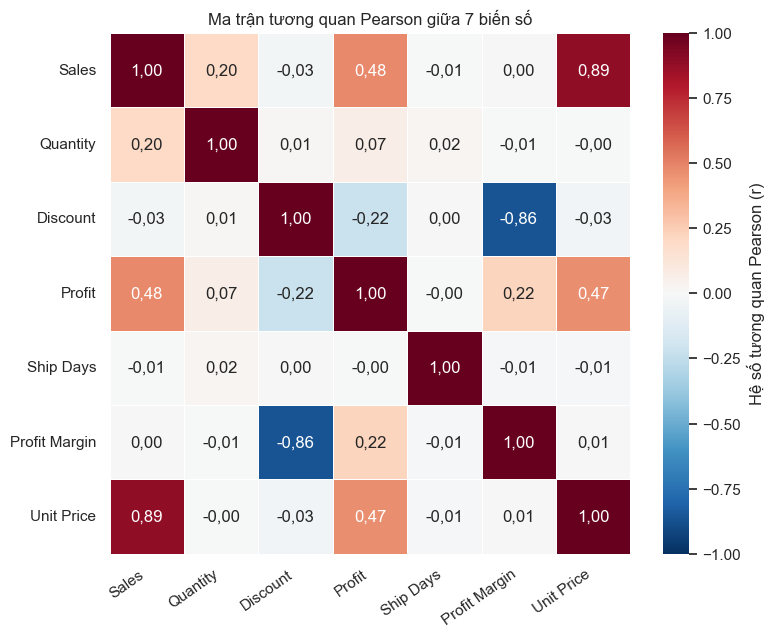

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/3_4_correlation_heatmap.png
Unit Price – Sales: 0,89 | Profit Margin – Discount: -0,86 | Profit – Sales: 0,48 | Profit – Discount: -0,22
Các cặp có |r| ≥ 0,8:


,Cặp biến,Hệ số r,Đề xuất,Lý do
0,Sales – Unit Price,0.889,Giữ Sales; cân nhắc bỏ Unit Price khi mô hình hóa,Unit Price = Sales / Quantity và phần lớn dòng...
1,Discount – Profit Margin,-0.864,Giữ Discount; KHÔNG dùng Profit Margin làm biế...,Profit Margin = Profit / Sales là hàm của chín...


In [24]:
bien_so = ["Sales", "Quantity", "Discount", "Profit", "Ship Days", "Profit Margin", "Unit Price"]
tuong_quan = df[bien_so].corr(method="pearson")

nhan = np.vectorize(lambda x: vn(x, 2))(tuong_quan.values)  # ghi hệ số theo dấu phẩy thập phân
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(tuong_quan, annot=nhan, fmt="", cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"label": "Hệ số tương quan Pearson (r)"}, ax=ax)
ax.set_title("Ma trận tương quan Pearson giữa 7 biến số")
plt.xticks(rotation=35, ha="right")
fig.tight_layout()
fig.savefig(FIGURES / "3_4_correlation_heatmap.png", dpi=200, facecolor="white")
plt.show()
print("Đã lưu hình:", FIGURES / "3_4_correlation_heatmap.png")

r_up_sales = tuong_quan.loc["Unit Price", "Sales"]
r_pm_disc = tuong_quan.loc["Profit Margin", "Discount"]
r_profit_sales = tuong_quan.loc["Profit", "Sales"]
r_profit_disc = tuong_quan.loc["Profit", "Discount"]
print(f"Unit Price – Sales: {vn(r_up_sales, 2)} | Profit Margin – Discount: {vn(r_pm_disc, 2)} | "
      f"Profit – Sales: {vn(r_profit_sales, 2)} | Profit – Discount: {vn(r_profit_disc, 2)}")

ly_do = {
    frozenset(["Sales", "Unit Price"]): (
        "Giữ Sales; cân nhắc bỏ Unit Price khi mô hình hóa",
        "Unit Price = Sales / Quantity và phần lớn dòng hàng có Quantity nhỏ, nên Unit Price gần như lặp lại thông tin của Sales."),
    frozenset(["Discount", "Profit Margin"]): (
        "Giữ Discount; KHÔNG dùng Profit Margin làm biến đầu vào khi dự đoán đơn lỗ",
        "Profit Margin = Profit / Sales là hàm của chính lợi nhuận (đại lượng cần dự đoán), nên dùng nó là rò rỉ nhãn; "
        "phần thông tin hữu ích của nó (ảnh hưởng của giảm giá) đã nằm trong Discount."),
}
cap_cao = []
for i, a in enumerate(bien_so):
    for b in bien_so[i + 1:]:
        r = tuong_quan.loc[a, b]
        if abs(r) >= 0.8:
            de_xuat, li_do = ly_do.get(frozenset([a, b]), ("Cần xem xét thủ công", "Cặp biến mới phát sinh, chưa có lập luận."))
            cap_cao.append({"Cặp biến": f"{a} – {b}", "Hệ số r": round(r, 3), "Đề xuất": de_xuat, "Lý do": li_do})
bang_cap = pd.DataFrame(cap_cao)
print("Các cặp có |r| ≥ 0,8:")
display(bang_cap)

**Rò rỉ nhãn (label leakage)** xảy ra khi một biến đầu vào chứa thông tin suy ra trực tiếp từ nhãn cần dự đoán, khiến mô hình "biết trước đáp án" và cho kết quả đẹp giả tạo. Vì `Profit Margin = Profit / Sales`, nó không được dùng làm đầu vào khi dự đoán đơn lỗ (`Profit < 0`).

### 3.4.3. Phân tích thành phần chính (PCA)

**PCA** biến các biến số ban đầu thành các **thành phần chính** (PC) mới, không tương quan với nhau, sắp xếp theo lượng thông tin mà chúng giữ được. **Phương sai giải thích** của một thành phần là tỷ lệ tổng biến thiên của dữ liệu mà thành phần đó nắm giữ; cộng dồn các thành phần đầu cho biết cần giữ bao nhiêu thành phần để không mất nhiều thông tin.

Vì các biến có thang đo rất khác nhau nên phải chuẩn hóa Z-score trước khi chạy PCA, nếu không biến có giá trị lớn (Sales) sẽ áp đảo.

,Thành phần,Phương sai giải thích,Tích lũy
0,PC1,0.3343,0.3343
1,PC2,0.2639,0.5982
2,PC3,0.1459,0.7441
3,PC4,0.1402,0.8843
4,PC5,0.0840,0.9682
5,PC6,0.0193,0.9875
6,PC7,0.0125,1.0000


Cần 4 thành phần để đạt ≥ 80% phương sai (tích lũy 88,4%)
Cần 5 thành phần để đạt ≥ 90% phương sai (tích lũy 96,8%)


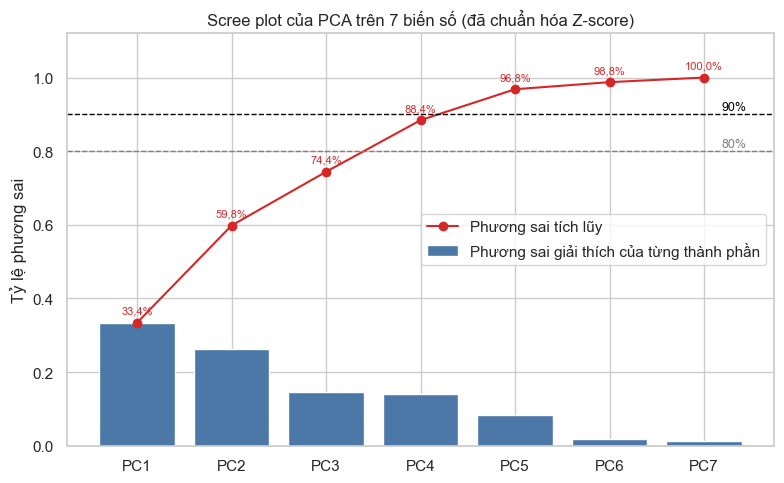

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/3_4_pca_scree.png


In [25]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Z = StandardScaler().fit_transform(df[bien_so])
pca = PCA(n_components=len(bien_so), random_state=42).fit(Z)
phuong_sai = pca.explained_variance_ratio_
tich_luy = np.cumsum(phuong_sai)
ten_pc = [f"PC{i + 1}" for i in range(len(bien_so))]

bang_pca = pd.DataFrame({"Thành phần": ten_pc, "Phương sai giải thích": phuong_sai, "Tích lũy": tich_luy})
display(bang_pca.round(4))
so_pc_80 = int(np.argmax(tich_luy >= 0.80) + 1)
so_pc_90 = int(np.argmax(tich_luy >= 0.90) + 1)
print(f"Cần {so_pc_80} thành phần để đạt ≥ 80% phương sai (tích lũy {vn(100 * tich_luy[so_pc_80 - 1], 1)}%)")
print(f"Cần {so_pc_90} thành phần để đạt ≥ 90% phương sai (tích lũy {vn(100 * tich_luy[so_pc_90 - 1], 1)}%)")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(ten_pc, phuong_sai, color="#4C78A8", label="Phương sai giải thích của từng thành phần")
ax.plot(ten_pc, tich_luy, marker="o", color="#D62728", label="Phương sai tích lũy")
for muc, mau in ((0.8, "gray"), (0.9, "black")):
    ax.axhline(muc, ls="--", lw=1, color=mau)
    ax.text(len(bien_so) - 0.55, muc + 0.012, f"{int(muc * 100)}%", ha="right", fontsize=9, color=mau)
for i, v in enumerate(tich_luy):
    ax.text(i, v + 0.025, vn(100 * v, 1) + "%", ha="center", fontsize=8, color="#D62728")
ax.set_ylim(0, 1.12)
ax.set_ylabel("Tỷ lệ phương sai")
ax.set_title("Scree plot của PCA trên 7 biến số (đã chuẩn hóa Z-score)")
ax.legend(loc="center right")
fig.tight_layout()
fig.savefig(FIGURES / "3_4_pca_scree.png", dpi=200, facecolor="white")
plt.show()
print("Đã lưu hình:", FIGURES / "3_4_pca_scree.png")

In [26]:
loadings = pd.DataFrame(pca.components_[:4].T, index=bien_so, columns=["PC1", "PC2", "PC3", "PC4"])
print("Bảng loadings (hệ số của từng biến trong mỗi thành phần):")
display(loadings.round(3))

Bảng loadings (hệ số của từng biến trong mỗi thành phần):


,PC1,PC2,PC3,PC4
Sales,0.559,-0.304,0.024,-0.018
Quantity,0.103,-0.082,0.716,-0.667
Discount,-0.272,-0.635,-0.023,0.007
Profit,0.484,-0.005,-0.029,0.047
Ship Days,-0.011,-0.004,0.682,0.731
Profit Margin,0.260,0.643,0.020,-0.022
Unit Price,0.548,-0.291,-0.141,0.132


**Diễn giải các thành phần** (loading càng lớn về giá trị tuyệt đối thì biến càng đóng góp nhiều cho thành phần):

- **PC1 (33,4%)**: Sales (0,56), Unit Price (0,55) và Profit (0,48) cùng dấu và lớn → đại diện cho **quy mô giá trị giao dịch và lợi nhuận tuyệt đối**.
- **PC2 (26,4%)**: Profit Margin (+0,64) đối lập với Discount (−0,63) → đại diện cho **mối quan hệ nghịch giữa mức giảm giá và tỷ suất lợi nhuận**.
- **PC3 (14,6%) và PC4 (14,0%)**: chủ yếu được tạo từ Ship Days và Quantity (loading khoảng ±0,7). Hai biến này hầu như không tương quan với các biến còn lại (|r| của Ship Days với biến khác không quá 0,02), nên mỗi biến gần như tự tạo thành một thành phần (mỗi thành phần chiếm khoảng 1/7 = 14,3% phương sai).

**Kết luận trung thực:** cần **4 thành phần** để đạt ≥ 80% phương sai (88,4%) và **5 thành phần** để đạt ≥ 90% (96,8%). Từ 7 biến xuống 4–5 thành phần chỉ giảm được khoảng 29–43% số chiều, và các thành phần mới khó diễn giải hơn biến gốc. Lý do: bộ dữ liệu chỉ có 7 biến, phần lớn ít liên quan lẫn nhau (ngoài hai cụm Sales–Unit Price–Profit và Discount–Profit Margin), nên không có nhiều thông tin dư thừa để nén. **PCA không rút gọn hiệu quả với bộ dữ liệu này**; đề tài giữ các biến gốc để bảo đảm khả năng diễn giải và dùng PCA chủ yếu để hiểu cấu trúc dữ liệu.

### 3.4.4. Rút gọn số dòng bằng gộp (aggregation)

**Gộp dữ liệu (aggregation)** là tổng hợp nhiều dòng thành một dòng đại diện (dùng tổng, trung bình, đếm…). Bảng gốc ở mức *dòng sản phẩm*; ta gộp lên hai mức phân tích khác:

- **Mức đơn hàng** (`orders_level`): mỗi dòng là một đơn hàng, phục vụ phân tích giỏ hàng và luật kết hợp.
- **Mức khách hàng** (`customers_level`): mỗi dòng là một khách hàng, phục vụ phân cụm RFM.

Sau khi gộp phải kiểm tra tổng `Sales` và `Profit` của bảng gộp bằng đúng bảng gốc để chắc chắn không mất hay nhân đôi dòng nào.

In [27]:
cot_hang_theo_don = ["Order Date", "Customer ID", "Segment", "Region", "Ship Mode", "Ship Days"]
nhom_don = df.groupby("Order ID", sort=False)
for c in cot_hang_theo_don:  # các cột này phải giống nhau trong cùng một đơn thì mới lấy giá trị đầu tiên được
    assert nhom_don[c].nunique().eq(1).all(), f"{c} không cố định trong một đơn"

orders_level = nhom_don.agg(**{
    "Order Date": ("Order Date", "first"), "Customer ID": ("Customer ID", "first"), "Segment": ("Segment", "first"),
    "Region": ("Region", "first"), "Ship Mode": ("Ship Mode", "first"), "Ship Days": ("Ship Days", "first"),
    "n_lines": ("Product ID", "size"), "total_quantity": ("Quantity", "sum"),
    "total_sales": ("Sales", "sum"), "total_profit": ("Profit", "sum"), "avg_discount": ("Discount", "mean"),
    "sub_categories": ("Sub-Category", lambda s: "; ".join(sorted(s.unique()))),
    "is_returned": ("is_returned", "max"),
}).reset_index()

n_don_nhieu_dong = int((orders_level["n_lines"] >= 2).sum())
print(f"orders_level: {len(orders_level)} dòng (từ {len(df)} dòng gốc) | đơn có ≥ 2 dòng sản phẩm: {n_don_nhieu_dong}")
assert abs(orders_level["total_sales"].sum() - df["Sales"].sum()) < 0.01
assert abs(orders_level["total_profit"].sum() - df["Profit"].sum()) < 0.01
assert orders_level["n_lines"].sum() == len(df)
print(f"Tổng Sales: gốc {vn(df['Sales'].sum(), 2)} = gộp {vn(orders_level['total_sales'].sum(), 2)} | "
      f"tổng Profit: gốc {vn(df['Profit'].sum(), 2)} = gộp {vn(orders_level['total_profit'].sum(), 2)}")
display(orders_level.head(3))

orders_level: 5009 dòng (từ 9993 dòng gốc) | đơn có ≥ 2 dòng sản phẩm: 2471
Tổng Sales: gốc 2.296.919,49 = gộp 2.296.919,49 | tổng Profit: gốc 286.409,08 = gộp 286.409,08


,Order ID,Order Date,Customer ID,Segment,Region,Ship Mode,Ship Days,n_lines,total_quantity,total_sales,total_profit,avg_discount,sub_categories,is_returned
0,CA-2018-152156,2018-11-08,CG-12520,Consumer,South,Second Class,3,2,5,993.9000,261.4956,0.000,Bookcases; Chairs,0
1,CA-2018-138688,2018-06-12,DV-13045,Corporate,West,Second Class,4,1,2,14.6200,6.8714,0.000,Labels,0
2,US-2017-108966,2017-10-11,SO-20335,Consumer,South,Standard Class,7,2,7,979.9455,-380.5146,0.325,Storage; Tables,0


In [28]:
# Segment cố định theo khách; Region thì KHÔNG (khách mua ở nhiều vùng) nên lấy vùng có nhiều đơn nhất
assert orders_level.groupby("Customer ID")["Segment"].nunique().eq(1).all()
n_khach_nhieu_vung = int((orders_level.groupby("Customer ID")["Region"].nunique() > 1).sum())
print(f"Số khách có đơn ở nhiều hơn một vùng: {n_khach_nhieu_vung}/{orders_level['Customer ID'].nunique()} → Region của khách = vùng có nhiều đơn nhất (hòa thì lấy vùng mua gần nhất)")

vung_chinh = (orders_level.groupby(["Customer ID", "Region"])
              .agg(so_don=("Order ID", "size"), gan_nhat=("Order Date", "max")).reset_index()
              .sort_values(["Customer ID", "so_don", "gan_nhat"], ascending=[True, False, False])
              .drop_duplicates("Customer ID")[["Customer ID", "Region"]])

customers_level = (orders_level.groupby("Customer ID")
                   .agg(Segment=("Segment", "first"), n_orders=("Order ID", "size"),
                        total_sales=("total_sales", "sum"), total_profit=("total_profit", "sum"),
                        first_order_date=("Order Date", "min"), last_order_date=("Order Date", "max"),
                        return_rate=("is_returned", "mean")).reset_index()
                   .merge(vung_chinh, on="Customer ID", how="left", validate="one_to_one"))
customers_level = customers_level[["Customer ID", "Segment", "Region", "n_orders", "total_sales", "total_profit",
                                   "first_order_date", "last_order_date", "return_rate"]]

print(f"customers_level: {len(customers_level)} dòng (từ {len(orders_level)} đơn hàng)")
assert abs(customers_level["total_sales"].sum() - df["Sales"].sum()) < 0.01
assert abs(customers_level["total_profit"].sum() - df["Profit"].sum()) < 0.01
assert customers_level["n_orders"].sum() == len(orders_level)
print("Kiểm tra tổng Sales, Profit và tổng số đơn: khớp với bảng gốc")
display(customers_level.head(3))

tom_tat_34 = [
    {"Kỹ thuật": "Xóa cột hằng", "Đối tượng": ", ".join(cot_hang), "Phương pháp": "Tìm cột chỉ có một giá trị duy nhất",
     "Kết quả": "1 cột hằng (chỉ có giá trị United States)", "Quyết định": "Xóa khỏi superstore_clean.csv"},
    {"Kỹ thuật": "Xóa cột dư thừa", "Đối tượng": ", ".join(cot_du_thua),
     "Phương pháp": "Row ID là số thứ tự dòng; Customer Name quan hệ 1–1 với Customer ID (793 ↔ 793)",
     "Kết quả": f"Số cột {so_cot_truoc} → {so_cot_sau}", "Quyết định": "Xóa khỏi superstore_clean.csv"},
    {"Kỹ thuật": "Chọn đặc trưng bằng tương quan", "Đối tượng": ", ".join(bien_so), "Phương pháp": "Ma trận Pearson, ngưỡng |r| ≥ 0,8",
     "Kết quả": f"{len(bang_cap)} cặp: Sales–Unit Price (r = {vn(r_up_sales, 2)}), Discount–Profit Margin (r = {vn(r_pm_disc, 2)})",
     "Quyết định": "Chỉ đề xuất, không xóa cột: giữ Sales và Discount; không dùng Profit Margin làm đầu vào khi dự đoán đơn lỗ"},
    {"Kỹ thuật": "PCA", "Đối tượng": "7 biến số (Z-score)", "Phương pháp": "PCA giữ đủ 7 thành phần để đo phương sai",
     "Kết quả": f"{so_pc_80} thành phần đạt {vn(100 * tich_luy[so_pc_80 - 1], 1)}% (≥ 80%); {so_pc_90} thành phần đạt {vn(100 * tich_luy[so_pc_90 - 1], 1)}% (≥ 90%)",
     "Quyết định": "Không dùng PCA làm rút gọn chính vì nén không hiệu quả; giữ biến gốc"},
    {"Kỹ thuật": "Gộp theo đơn hàng", "Đối tượng": "Order ID", "Phương pháp": "groupby Order ID; tổng, trung bình, đếm",
     "Kết quả": f"{len(df):,} → {len(orders_level):,} dòng ({n_don_nhieu_dong:,} đơn có ≥ 2 dòng sản phẩm); tổng Sales, Profit khớp".replace(",", "."),
     "Quyết định": "Lưu orders_level.csv"},
    {"Kỹ thuật": "Gộp theo khách hàng", "Đối tượng": "Customer ID", "Phương pháp": "groupby Customer ID từ bảng đơn hàng; Region = vùng có nhiều đơn nhất",
     "Kết quả": f"{len(orders_level):,} → {len(customers_level):,} dòng; {n_khach_nhieu_vung} khách mua ở nhiều vùng; tổng Sales, Profit khớp".replace(",", "."),
     "Quyết định": "Lưu customers_level.csv"},
]

Số khách có đơn ở nhiều hơn một vùng: 766/793 → Region của khách = vùng có nhiều đơn nhất (hòa thì lấy vùng mua gần nhất)


customers_level: 793 dòng (từ 5009 đơn hàng)
Kiểm tra tổng Sales, Profit và tổng số đơn: khớp với bảng gốc


,Customer ID,Segment,Region,n_orders,total_sales,total_profit,first_order_date,last_order_date,return_rate
0,AA-10315,Consumer,Central,5,5563.560,-362.8825,2016-03-31,2019-06-29,0.0
1,AA-10375,Consumer,West,9,1056.390,277.3824,2016-04-21,2019-12-11,0.0
2,AA-10480,Consumer,Central,4,1790.512,435.8274,2016-05-04,2019-04-15,0.0


## Bước 3.5. Rời rạc hóa dữ liệu

**Rời rạc hóa** chuyển một biến số liên tục thành một số ít nhóm có tên (ví dụ từ mức giảm giá 0,15 thành nhóm "Thấp"). Việc này giúp dễ diễn giải, dễ so sánh giữa các nhóm và cho phép dùng các thuật toán làm việc với biến phân loại.

### 3.5.1. Rời rạc hóa Discount thành `Discount_Level`

Ba nhóm: **Không** (Discount = 0), **Thấp** (0 < Discount ≤ 0,2), **Cao** (Discount > 0,2). Với mỗi nhóm, tính số dòng, tổng và trung bình Profit, và tỷ lệ đơn lỗ (đơn lỗ là dòng hàng có `Profit < 0`).

TRƯỚC – các mức Discount: [0.0, 0.1, 0.15, 0.2, 0.3, 0.32, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8]
SAU – kết quả theo nhóm:


,Nhóm,Số dòng,Tổng Profit,Profit trung bình,Tỷ lệ đơn lỗ (%)
0,Không,4798,320987.60,66.90,0.00
1,Thấp,3803,100785.47,26.50,13.75
2,Cao,1392,-135364.00,-97.24,96.77


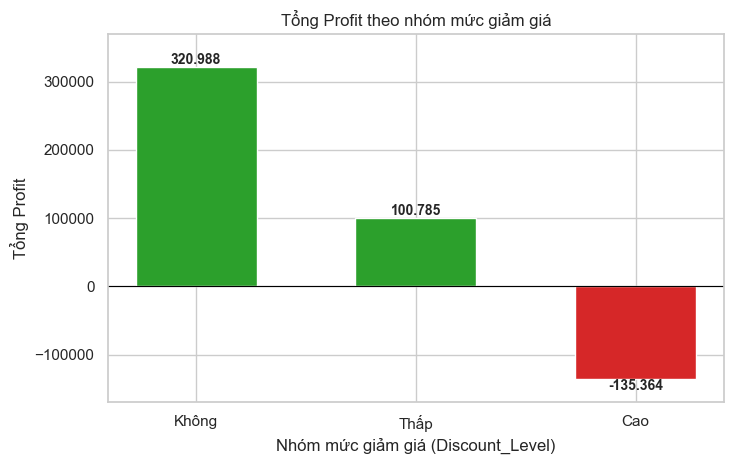

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/3_5_discount_level_profit.png


In [29]:
d = df["Discount"]
df["Discount_Level"] = pd.Categorical(np.select([d == 0, d <= 0.2], ["Không", "Thấp"], default="Cao"),
                                      categories=["Không", "Thấp", "Cao"], ordered=True)
print("TRƯỚC – các mức Discount:", sorted(df["Discount"].unique().tolist()))

bang_giam_gia = (df.groupby("Discount_Level", observed=True)
                   .agg(so_dong=("Profit", "size"), tong_profit=("Profit", "sum"),
                        profit_tb=("Profit", "mean"), ty_le_lo=("Profit", lambda s: 100 * (s < 0).mean()))
                   .reset_index())
bang_giam_gia.columns = ["Nhóm", "Số dòng", "Tổng Profit", "Profit trung bình", "Tỷ lệ đơn lỗ (%)"]
bang_giam_gia["Nhóm"] = bang_giam_gia["Nhóm"].astype(str)
print("SAU – kết quả theo nhóm:")
display(bang_giam_gia.round(2))

fig, ax = plt.subplots(figsize=(7.5, 4.8))
mau = ["#2CA02C" if v >= 0 else "#D62728" for v in bang_giam_gia["Tổng Profit"]]
ax.bar(bang_giam_gia["Nhóm"], bang_giam_gia["Tổng Profit"], color=mau, width=0.55)
for i, v in enumerate(bang_giam_gia["Tổng Profit"]):
    ax.text(i, v, vn(v, 0), ha="center", va="bottom" if v >= 0 else "top", fontsize=10, fontweight="bold")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Nhóm mức giảm giá (Discount_Level)")
ax.set_ylabel("Tổng Profit")
ax.set_title("Tổng Profit theo nhóm mức giảm giá")
ax.set_ylim(min(bang_giam_gia["Tổng Profit"]) * 1.25, max(bang_giam_gia["Tổng Profit"]) * 1.15)
fig.tight_layout()
fig.savefig(FIGURES / "3_5_discount_level_profit.png", dpi=200, facecolor="white")
plt.show()
print("Đã lưu hình:", FIGURES / "3_5_discount_level_profit.png")

### 3.5.2. Rời rạc hóa Sales: so sánh hai cách chia 4 nhóm

- **Chia theo tứ phân vị** (*equal-frequency*, `pd.qcut`): mỗi nhóm có **số dòng xấp xỉ bằng nhau**; khoảng giá trị của các nhóm khác nhau.
- **Chia độ rộng bằng nhau** (*equal-width*, `pd.cut`): mỗi nhóm có **khoảng giá trị bằng nhau**; số dòng mỗi nhóm có thể chênh lệch rất lớn.

Sales lệch phải mạnh (độ lệch 12,97 ở bước 3.3) nên hai cách này sẽ cho kết quả rất khác nhau.

In [30]:
df["Sales_Quartile"], mo_qcut = pd.qcut(df["Sales"], 4, labels=["Q1", "Q2", "Q3", "Q4"], retbins=True)
sales_dw, mo_cut = pd.cut(df["Sales"], 4, labels=["W1", "W2", "W3", "W4"], retbins=True)
mo_cut = np.array(mo_cut, dtype=float)
mo_cut[0] = df["Sales"].min()  # pandas nới mốc dưới thêm 0,1%; hiển thị theo giá trị nhỏ nhất thực tế

dem_q = df["Sales_Quartile"].value_counts().sort_index()
dem_w = sales_dw.value_counts().sort_index()
khoang = lambda mo, i: f"{vn(mo[i], 2)} – {vn(mo[i + 1], 2)}"
bang_chia = pd.DataFrame({
    "Nhóm": [1, 2, 3, 4],
    "Tứ phân vị – khoảng Sales": [khoang(mo_qcut, i) for i in range(4)],
    "Tứ phân vị – số dòng": dem_q.values,
    "Độ rộng bằng nhau – khoảng Sales": [khoang(mo_cut, i) for i in range(4)],
    "Độ rộng bằng nhau – số dòng": dem_w.values,
})
print("Mốc chia theo tứ phân vị:", [vn(x, 2) for x in mo_qcut])
display(bang_chia)
ty_le_nhom_w1 = 100 * dem_w.iloc[0] / len(df)
print(f"Chia độ rộng bằng nhau dồn {vn(ty_le_nhom_w1, 2)}% số dòng vào nhóm đầu tiên.")

Mốc chia theo tứ phân vị: ['0,44', '17,28', '54,48', '209,94', '22.638,48']


,Nhóm,Tứ phân vị – khoảng Sales,Tứ phân vị – số dòng,Độ rộng bằng nhau – khoảng Sales,Độ rộng bằng nhau – số dòng
0,1,"0,44 – 17,28",2501,"0,44 – 5.659,95",9978
1,2,"17,28 – 54,48",2496,"5.659,95 – 11.319,46",12
2,3,"54,48 – 209,94",2499,"11.319,46 – 16.978,97",1
3,4,"209,94 – 22.638,48",2497,"16.978,97 – 22.638,48",2


Chia độ rộng bằng nhau dồn 99,85% số dòng vào nhóm đầu tiên.


**Kết luận:** chia theo **tứ phân vị** phù hợp hơn. Vì Sales lệch phải rất mạnh, chia độ rộng bằng nhau dồn 9.978 trong 9.993 dòng (99,85%) vào nhóm đầu và chỉ để 3 dòng cho hai nhóm cuối, nên không còn khả năng phân biệt các dòng hàng. Chia theo tứ phân vị cho bốn nhóm cân bằng (mỗi nhóm khoảng 2.500 dòng), phản ánh đúng phân phối thực tế nên thích hợp làm biến phân loại và làm bộ lọc trên dashboard. Cột `Sales_Quartile` được giữ lại trong `superstore_clean.csv`; cách chia độ rộng bằng nhau chỉ dùng để so sánh.

### 3.5.3. Chấm điểm RFM cho từng khách hàng

**RFM** đánh giá khách hàng bằng ba chỉ số:

- **R (Recency)**: số ngày từ lần mua cuối đến ngày tham chiếu (càng nhỏ càng tốt).
- **F (Frequency)**: số đơn hàng khác nhau đã mua.
- **M (Monetary)**: tổng giá trị đã mua (tổng Sales).

Mỗi chỉ số được chấm điểm 1–5 bằng `pd.qcut` (5 nhóm bằng tần suất). **R đảo ngược** (mua càng gần thì điểm càng cao). **F** dùng `rank(method="first")` trước khi chia vì có rất nhiều khách có cùng số đơn (`qcut` không chia được khi nhiều giá trị trùng); hệ quả là những khách cùng số đơn có thể rơi vào hai mức điểm khác nhau, được phân theo thứ tự xuất hiện trong dữ liệu. Ngày tham chiếu là ngày đặt hàng lớn nhất cộng 1 ngày.

In [31]:
ngay_tham_chieu = df["Order Date"].max() + pd.Timedelta(days=1)
print("Ngày tham chiếu:", ngay_tham_chieu.date())

rfm = customers_level[["Customer ID", "Segment"]].copy()
rfm["Recency"] = (ngay_tham_chieu - customers_level["last_order_date"]).dt.days
rfm["Frequency"] = customers_level["n_orders"]
rfm["Monetary"] = customers_level["total_sales"]
rfm["R_score"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F_score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M_score"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM_Score"] = rfm["R_score"].astype(str) + rfm["F_score"].astype(str) + rfm["M_score"].astype(str)
rfm["RFM_Total"] = rfm[["R_score", "F_score", "M_score"]].sum(axis=1)

print("Thống kê R, F, M:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))
print(f"R trung vị: {rfm['Recency'].median():.0f} ngày | F trung bình: {vn(rfm['Frequency'].mean(), 1)} đơn "
      f"({rfm['Frequency'].min()}–{rfm['Frequency'].max()}) | M trung vị: {vn(rfm['Monetary'].median(), 0)}")

bang_rfm = pd.DataFrame({"Điểm": [1, 2, 3, 4, 5],
                         "Số khách (R)": rfm["R_score"].value_counts().sort_index().values,
                         "Số khách (F)": rfm["F_score"].value_counts().sort_index().values,
                         "Số khách (M)": rfm["M_score"].value_counts().sort_index().values})
print("Số khách theo từng mức điểm:")
display(bang_rfm)
n_khach_555 = int((rfm["RFM_Score"] == "555").sum())
print(f"Số khách đạt RFM_Score = '555' (mua gần đây, thường xuyên, chi tiêu cao): {n_khach_555}")
print(f"Phân bố RFM_Total: {rfm['RFM_Total'].min()}–{rfm['RFM_Total'].max()}, trung bình {vn(rfm['RFM_Total'].mean(), 1)}")

Ngày tham chiếu: 2019-12-31
Thống kê R, F, M:


,Recency,Frequency,Monetary
count,793.00,793.00,793.00
mean,147.77,6.32,2896.49
std,186.09,2.55,2628.41
min,1.00,1.00,4.83
25%,31.00,5.00,1146.05
50%,76.00,6.00,2256.39
75%,184.00,8.00,3785.28
max,1165.00,17.00,25043.05


R trung vị: 76 ngày | F trung bình: 6,3 đơn (1–17) | M trung vị: 2.256
Số khách theo từng mức điểm:


,Điểm,Số khách (R),Số khách (F),Số khách (M)
0,1,159,159,159
1,2,157,158,158
2,3,159,159,159
3,4,156,158,158
4,5,162,159,159


Số khách đạt RFM_Score = '555' (mua gần đây, thường xuyên, chi tiêu cao): 22
Phân bố RFM_Total: 3–15, trung bình 9,0


## Xuất dữ liệu cuối của Mục III

Lưu các file dùng cho các bước sau:

- `superstore_clean.csv`: dữ liệu mức dòng sau toàn bộ bước 3.1–3.5 (đã xóa cột thừa, có `Discount_Level`, `Sales_Quartile`), dễ đọc, dùng cho EDA và dashboard.
- `orders_level.csv`, `customers_level.csv`, `rfm_customers.csv`.
- `superstore_model_ready.csv` (từ bước 3.3) được **giữ nguyên**, không ghi lại.
- Các bảng trong `reports/` để làm Bảng 3.4 – 3.7 của báo cáo.

In [32]:
df["Discount_Level"] = df["Discount_Level"].astype(str)
df["Sales_Quartile"] = df["Sales_Quartile"].astype(str)

df.to_csv(PROCESSED / "superstore_clean.csv", index=False, encoding="utf-8-sig")
orders_level.to_csv(PROCESSED / "orders_level.csv", index=False, encoding="utf-8-sig")
customers_level.to_csv(PROCESSED / "customers_level.csv", index=False, encoding="utf-8-sig")
rfm.to_csv(PROCESSED / "rfm_customers.csv", index=False, encoding="utf-8-sig")

bang_tom_tat_34 = pd.DataFrame(tom_tat_34, columns=["Kỹ thuật", "Đối tượng", "Phương pháp", "Kết quả", "Quyết định"])
bang_tom_tat_34.to_csv(REPORTS / "3_4_reduction_summary.csv", index=False, encoding="utf-8-sig")

tom_tat_35 = [
    {"Kỹ thuật": "Rời rạc hóa Discount", "Cột áp dụng": "Discount → Discount_Level",
     "Cách chia": "Không (= 0), Thấp (0 < x ≤ 0,2), Cao (> 0,2)",
     "Kết quả": "; ".join(f"{r['Nhóm']}: {vn(r['Số dòng'])} dòng, tổng Profit {vn(r['Tổng Profit'], 0)}" for _, r in bang_giam_gia.iterrows()),
     "Nhận xét": "Nhóm Cao gây lỗ; nhóm Không và Thấp sinh lời"},
    {"Kỹ thuật": "Chia Sales theo tứ phân vị (equal-frequency)", "Cột áp dụng": "Sales → Sales_Quartile",
     "Cách chia": "pd.qcut, 4 nhóm Q1–Q4; mốc " + " / ".join(vn(x, 2) for x in mo_qcut[1:4]),
     "Kết quả": " / ".join(vn(x) for x in dem_q.values) + " dòng",
     "Nhận xét": "Bốn nhóm cân bằng; được chọn và lưu vào superstore_clean.csv"},
    {"Kỹ thuật": "Chia Sales độ rộng bằng nhau (equal-width)", "Cột áp dụng": "Sales (chỉ để so sánh)",
     "Cách chia": "pd.cut, 4 nhóm bằng nhau về khoảng giá trị",
     "Kết quả": " / ".join(vn(x) for x in dem_w.values) + " dòng",
     "Nhận xét": f"Dồn {vn(ty_le_nhom_w1, 2)}% số dòng vào nhóm đầu do Sales lệch phải; không dùng"},
    {"Kỹ thuật": "Chấm điểm RFM", "Cột áp dụng": "Recency, Frequency, Monetary → R_score, F_score, M_score, RFM_Score, RFM_Total",
     "Cách chia": f"pd.qcut 5 nhóm (R đảo ngược, F dùng rank first); ngày tham chiếu {ngay_tham_chieu.date()}",
     "Kết quả": f"Mỗi mức điểm khoảng 156–162 khách; {n_khach_555} khách đạt 555",
     "Nhận xét": "Dùng làm đầu vào cho phân cụm khách hàng ở mục 4.2"},
]
bang_tom_tat_35 = pd.DataFrame(tom_tat_35)
bang_tom_tat_35.to_csv(REPORTS / "3_5_discretization_summary.csv", index=False, encoding="utf-8-sig")

# Các bảng chi tiết để làm Bảng 3.4 – 3.7
bang_pca.to_csv(REPORTS / "3_4_pca_variance.csv", index=False, encoding="utf-8-sig")
loadings.reset_index(names="Biến").to_csv(REPORTS / "3_4_pca_loadings.csv", index=False, encoding="utf-8-sig")
bang_cap.to_csv(REPORTS / "3_4_correlation_pairs.csv", index=False, encoding="utf-8-sig")
bang_giam_gia.to_csv(REPORTS / "3_5_discount_level.csv", index=False, encoding="utf-8-sig")
bang_chia.to_csv(REPORTS / "3_5_sales_binning.csv", index=False, encoding="utf-8-sig")
bang_rfm.to_csv(REPORTS / "3_5_rfm_distribution.csv", index=False, encoding="utf-8-sig")

assert duong_model.stat().st_mtime == mtime_model_truoc, "superstore_model_ready.csv đã bị ghi đè"
print("superstore_model_ready.csv được giữ nguyên (không bị ghi lại).")
for ten, x in (("superstore_clean.csv", df), ("orders_level.csv", orders_level), ("customers_level.csv", customers_level), ("rfm_customers.csv", rfm)):
    print(f"Đã lưu data/processed/{ten}: {x.shape[0]:,} dòng × {x.shape[1]} cột".replace(",", "."))
print("Đã lưu các bảng trong reports/: 3_4_reduction_summary, 3_5_discretization_summary, 3_4_pca_variance, 3_4_pca_loadings, 3_4_correlation_pairs, 3_5_discount_level, 3_5_sales_binning, 3_5_rfm_distribution")

superstore_model_ready.csv được giữ nguyên (không bị ghi lại).
Đã lưu data/processed/superstore_clean.csv: 9.993 dòng × 33 cột
Đã lưu data/processed/orders_level.csv: 5.009 dòng × 14 cột
Đã lưu data/processed/customers_level.csv: 793 dòng × 9 cột
Đã lưu data/processed/rfm_customers.csv: 793 dòng × 10 cột
Đã lưu các bảng trong reports/: 3_4_reduction_summary, 3_5_discretization_summary, 3_4_pca_variance, 3_4_pca_loadings, 3_4_correlation_pairs, 3_5_discount_level, 3_5_sales_binning, 3_5_rfm_distribution


### Kiểm tra lại file đã lưu và đối chiếu kết quả kỳ vọng

In [33]:
kiem_clean = pd.read_csv(PROCESSED / "superstore_clean.csv", encoding="utf-8-sig", dtype={"Postal Code": str}, parse_dates=["Order Date", "Ship Date"])
kiem_rfm = pd.read_csv(PROCESSED / "rfm_customers.csv", encoding="utf-8-sig", dtype={"RFM_Score": str})
assert kiem_clean.shape == df.shape and kiem_clean.isna().sum().sum() == 0
assert not {"Row ID", "Customer Name", "Country/Region"} & set(kiem_clean.columns)
assert {"Discount_Level", "Sales_Quartile"} <= set(kiem_clean.columns)
assert (kiem_clean["Postal Code"].str.len() == 5).all() and kiem_rfm["RFM_Score"].str.len().eq(3).all()

nhom = bang_giam_gia.set_index("Nhóm")
mo_w = dem_w.tolist()
kiem_tra = {
    "Cột hằng chỉ có Country/Region": cot_hang == ["Country/Region"],
    "Customer ID ↔ Customer Name quan hệ 1–1": bool(quan_he_1_1),
    "Tương quan: Unit Price–Sales ≈ 0,89; Profit Margin–Discount ≈ −0,86": abs(r_up_sales - 0.89) < 0.01 and abs(r_pm_disc + 0.86) < 0.01,
    "Tương quan: Profit–Sales ≈ 0,48; Profit–Discount ≈ −0,22": abs(r_profit_sales - 0.48) < 0.01 and abs(r_profit_disc + 0.22) < 0.01,
    "PCA: tỷ lệ ≈ 0,334 / 0,264 / 0,146 / 0,140 / 0,084 / 0,019 / 0,012": np.allclose(phuong_sai, [0.334, 0.264, 0.146, 0.140, 0.084, 0.019, 0.012], atol=0.0015),
    "PCA: tích lũy 4 PC ≈ 88,4%; 5 PC ≈ 96,8%": abs(tich_luy[3] - 0.884) < 0.001 and abs(tich_luy[4] - 0.968) < 0.001,
    "orders_level: 5.009 dòng, 2.471 đơn có ≥ 2 dòng sản phẩm": len(orders_level) == 5009 and n_don_nhieu_dong == 2471,
    "customers_level: 793 dòng": len(customers_level) == 793,
    "Discount_Level: Không 4.798 dòng, ≈ +320.988": nhom.loc["Không", "Số dòng"] == 4798 and abs(nhom.loc["Không", "Tổng Profit"] - 320988) < 1,
    "Discount_Level: Thấp 3.803 dòng, ≈ +100.786": nhom.loc["Thấp", "Số dòng"] == 3803 and abs(nhom.loc["Thấp", "Tổng Profit"] - 100786) < 1,
    "Discount_Level: Cao 1.392 dòng, ≈ −135.364": nhom.loc["Cao", "Số dòng"] == 1392 and abs(nhom.loc["Cao", "Tổng Profit"] + 135364) < 1,
    "Sales tứ phân vị: mốc 17,28 / 54,48 / 209,94, mỗi nhóm ≈ 2.500 dòng": (np.allclose(mo_qcut[1:4], [17.28, 54.48, 209.94], atol=0.01) and all(2490 <= n <= 2510 for n in dem_q)),
    "Sales độ rộng bằng nhau: 9.978 / 12 / 1 / 2 dòng": mo_w == [9978, 12, 1, 2],
    "RFM: ngày tham chiếu 2019-12-31": str(ngay_tham_chieu.date()) == "2019-12-31",
    "RFM: R trung vị 76; F trung bình ≈ 6,3 (1–17); M trung vị ≈ 2.256": (rfm["Recency"].median() == 76 and abs(rfm["Frequency"].mean() - 6.3) < 0.05
                                                                     and rfm["Frequency"].min() == 1 and rfm["Frequency"].max() == 17 and abs(rfm["Monetary"].median() - 2256) < 1),
    "RFM: mỗi mức điểm 156–162 khách": all(156 <= n <= 162 for col in ("Số khách (R)", "Số khách (F)", "Số khách (M)") for n in bang_rfm[col]),
    "RFM: 22 khách đạt 555": n_khach_555 == 22,
}
for ten, ok in kiem_tra.items():
    print("ĐẠT " if ok else "LỆCH", "–", ten)
assert all(kiem_tra.values()), "Có kết quả lệch so với kỳ vọng, cần kiểm tra lại"
print()
print("Tất cả kết quả khớp kỳ vọng.")

ĐẠT  – Cột hằng chỉ có Country/Region
ĐẠT  – Customer ID ↔ Customer Name quan hệ 1–1
ĐẠT  – Tương quan: Unit Price–Sales ≈ 0,89; Profit Margin–Discount ≈ −0,86
ĐẠT  – Tương quan: Profit–Sales ≈ 0,48; Profit–Discount ≈ −0,22
ĐẠT  – PCA: tỷ lệ ≈ 0,334 / 0,264 / 0,146 / 0,140 / 0,084 / 0,019 / 0,012
ĐẠT  – PCA: tích lũy 4 PC ≈ 88,4%; 5 PC ≈ 96,8%
ĐẠT  – orders_level: 5.009 dòng, 2.471 đơn có ≥ 2 dòng sản phẩm
ĐẠT  – customers_level: 793 dòng
ĐẠT  – Discount_Level: Không 4.798 dòng, ≈ +320.988
ĐẠT  – Discount_Level: Thấp 3.803 dòng, ≈ +100.786
ĐẠT  – Discount_Level: Cao 1.392 dòng, ≈ −135.364
ĐẠT  – Sales tứ phân vị: mốc 17,28 / 54,48 / 209,94, mỗi nhóm ≈ 2.500 dòng
ĐẠT  – Sales độ rộng bằng nhau: 9.978 / 12 / 1 / 2 dòng
ĐẠT  – RFM: ngày tham chiếu 2019-12-31
ĐẠT  – RFM: R trung vị 76; F trung bình ≈ 6,3 (1–17); M trung vị ≈ 2.256
ĐẠT  – RFM: mỗi mức điểm 156–162 khách
ĐẠT  – RFM: 22 khách đạt 555

Tất cả kết quả khớp kỳ vọng.


### Kết luận bước 3.4 và 3.5

- **3.4:** đã xóa 3 cột (`Country/Region` là cột hằng, `Row ID` và `Customer Name` dư thừa), xác định 2 cặp biến tương quan cao (chỉ đề xuất, không xóa), PCA cho thấy cần 4–5 thành phần nên không nén hiệu quả, và gộp thành `orders_level` (5.009 dòng) và `customers_level` (793 dòng) với tổng Sales, Profit khớp bảng gốc.
- **3.5:** đã tạo `Discount_Level` (nhóm Cao gây lỗ), chọn chia Sales theo tứ phân vị, và chấm điểm RFM cho 793 khách hàng (22 khách đạt 555).
- **Dữ liệu sẵn sàng** cho EDA (`superstore_clean.csv`), phân cụm và luật kết hợp (`orders_level.csv`, `rfm_customers.csv`) và mô hình hóa (`superstore_model_ready.csv`) ở Chương IV.